# Проект №1: Анализ данных с временной структурой

**Выполнили:**
- Староверова Анна
- Богославская Анна 
- Павлеева Мария
- Зыкова Вероника 

In [213]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime
from itertools import product
from joblib import dump
import json
from pandas import DataFrame
import statsmodels.api as sm
from tqdm.auto import tqdm

from statsmodels.tsa.stattools import adfuller, kpss

from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


from pandas.plotting import autocorrelation_plot
from sklearn import decomposition, datasets
from sklearn import tree
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error


import warnings
warnings.filterwarnings('ignore')

import scipy.stats as scs
import statsmodels.api as sm

## 1. EDA основных данных

In [147]:
data = pd.read_csv('Project+1_2024+-+Data.csv', parse_dates=['Date'])
print(data.shape)
data.head(3)

(1543, 4)


,Date,Income,Outcome,Balance
0,2017-01-09,"1,34E+00","1,49E+00","-0,1559036386"
1,2017-01-10,"1,068610321","1,194182455","-0,1255721339"
2,2017-01-11,"0,944429115","0,9366625183","0,00776659662"


Text(0.5, 1.0, 'Balance (Target value)')

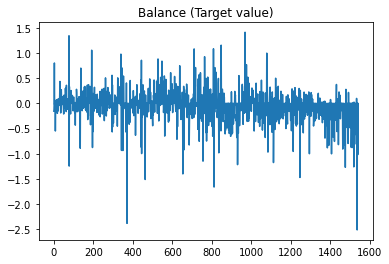

In [148]:
data['Balance'] = list(map(lambda x: x.replace(',', '.'), data['Balance']))
data['Income'] = list(map(lambda x: x.replace(',', '.'), data['Income']))
data['Outcome'] = list(map(lambda x: x.replace(',', '.'), data['Outcome']))
data['Date'] = pd.to_datetime(data.Date)

data['Balance'] = pd.to_numeric(data['Balance'])
data['Income'] = pd.to_numeric(data['Income'])
data['Outcome'] = pd.to_numeric(data['Outcome'])

data.Balance.plot()
plt.title('Balance (Target value)')

Видим, что под конец периода у нас становится больше отрицательных значений balance - можно подумать, что тренироваться и обучаться мы будем точно ДО момента, когда происходит это смещение, а потом наша модель должна будет отловить структурное изменение и отправить об этом сигнал, а также переобучиться.

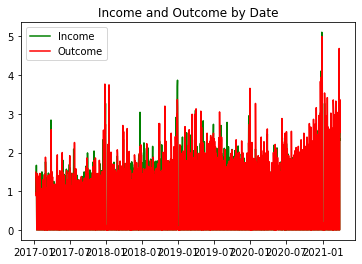

In [4]:
plt.figure()
plt.plot(data.Date, data.Income, color = 'green', label = 'Income')
# plt.figure()
plt.plot(data.Date, data.Outcome, color = 'red', label = 'Outcome')
plt.title('Income and Outcome by Date')
plt.legend()

Критерий Дики-Фуллера: p=0.000003


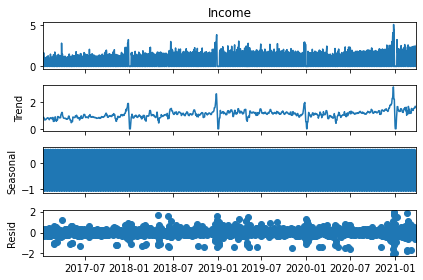

In [5]:
d1 = data.copy()
d1.set_index('Date', drop = False, inplace= True)
seasonal_decompose(d1.Income).plot()
print("Критерий Дики-Фуллера: p=%f" % sm.tsa.stattools.adfuller(d1.Income)[1])

Вообще выглядит так, что есть смысл отдельно предсказывать Income и Outcome, и из них уже делать вывод о Balance. Потому что: 

In [6]:
data.describe()

,Income,Outcome,Balance
count,1543.000000,1543.000000,1543.000000
mean,1.084967,1.133797,-0.048854
std,0.838711,0.901926,0.291950
min,0.000000,0.000000,-2.510000
25%,0.000000,0.000000,-0.142705
50%,1.330000,1.330000,0.000000
75%,1.670000,1.740000,0.037721
max,5.110000,5.000000,1.410000


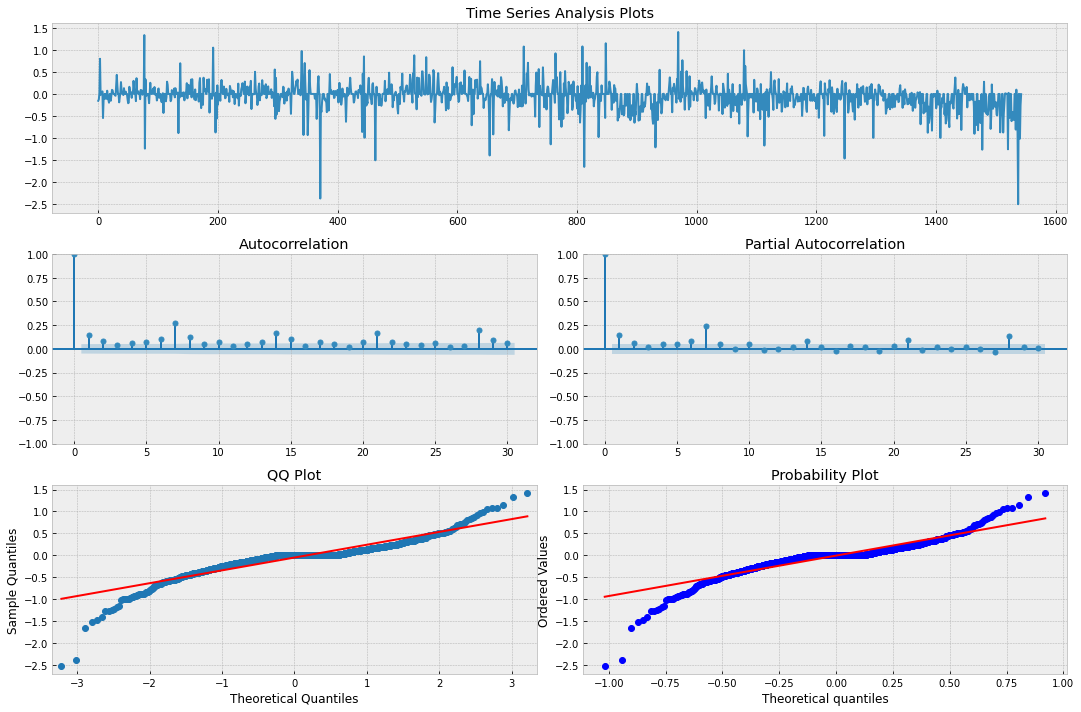

In [7]:
def tsplot(y, lags=None, figsize=(15, 10), style='bmh'):
    if not isinstance(y, pd.Series):
        y = pd.Series(y)
    with plt.style.context(style):    
        fig = plt.figure(figsize=figsize)
        #mpl.rcParams['font.family'] = 'Ubuntu Mono'
        layout = (3, 2)
        ts_ax = plt.subplot2grid(layout, (0, 0), colspan=2)
        acf_ax = plt.subplot2grid(layout, (1, 0))
        pacf_ax = plt.subplot2grid(layout, (1, 1))
        qq_ax = plt.subplot2grid(layout, (2, 0))
        pp_ax = plt.subplot2grid(layout, (2, 1))
        
        y.plot(ax=ts_ax)
        ts_ax.set_title('Time Series Analysis Plots')
        
        sm.graphics.tsa.plot_acf(y, lags=lags, ax=acf_ax, alpha=0.05)
        sm.graphics.tsa.plot_pacf(y, lags=lags, ax=pacf_ax, alpha=0.05)
        sm.qqplot(y, line='s', ax=qq_ax)
        qq_ax.set_title('QQ Plot')        
        scs.probplot(y, sparams=(y.mean(), y.std()), plot=pp_ax)

        plt.tight_layout()
    return

tsplot(data.Balance, lags=30)

Видим, что есть явная периодичность: пики на каждом седьмом значении - можно это использовать. 

In [8]:
data.sort_values(by = 'Balance', ascending= False).head(3)

,Date,Income,Outcome,Balance
969,2019-09-05,2.78,1.37,1.410000
77,2017-03-27,2.84,1.49,1.340000
848,2019-05-07,2.82,1.67,1.153604


In [9]:
data.sort_values(by = 'Balance', ascending= True).head(3)

,Date,Income,Outcome,Balance
1537,2021-03-26,2.17,4.69,-2.51
371,2018-01-15,1.36,3.75,-2.38
812,2019-04-01,1.47,3.13,-1.66


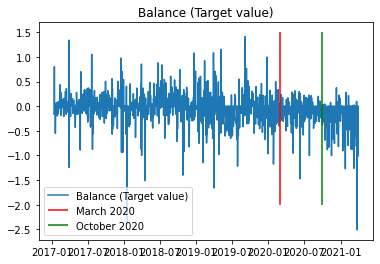

In [10]:
plt.plot(data.Date, data.Balance, label = 'Balance (Target value)')
plt.vlines(x = datetime.fromisoformat('2020-03-01'), ymin = -2, ymax = 1.5, color = 'red', label = 'March 2020')
plt.vlines(x = datetime.fromisoformat('2020-10-01'), ymin = -2, ymax = 1.5, color = 'green', label = 'October 2020')
plt.title('Balance (Target value)')
plt.legend()

Видим, что проблема с рядом началась примерно с началом пандемии в России (там сильно снизилась дисперсия, довольно немного положительных пиков стало), но что произошло в октябре?

In [149]:
# добавим всякие признаки от даты: день месяца, день недели, месяц, год 

data['Year'] = list(map(lambda x: x.year, data['Date']))
data['Month'] = list(map(lambda x: x.month, data['Date']))
data['DayofWeek'] = list(map(lambda x: x.dayofweek, data['Date']))
data['DayofMonth'] = list(map(lambda x: int(x.strftime("%d")), data['Date']))

Text(0.5, 1.0, 'Смотрим на хитмапу для Income')

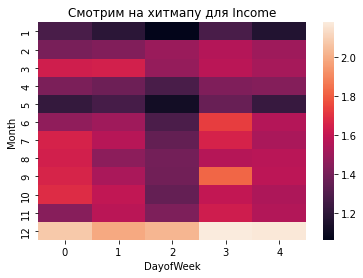

In [12]:
table_pivot = pd.pivot_table(data[data.DayofWeek.isin([0, 1, 2,3, 4])], values='Income', index=['Month'], columns=['DayofWeek'], aggfunc="mean")
sns.heatmap(table_pivot)
plt.title('Смотрим на хитмапу для Income')

<Axes: xlabel='DayofMonth', ylabel='Month'>

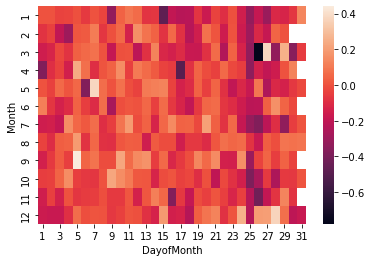

In [13]:
table_pivot_2 = pd.pivot_table(data, values='Balance', index=['Month'], columns=['DayofMonth'], aggfunc="mean")
sns.heatmap(table_pivot_2)

<Axes: xlabel='DayofMonth', ylabel='Month'>

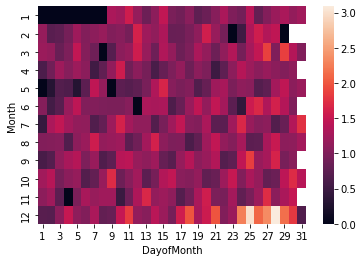

In [14]:
table_pivot_2 = pd.pivot_table(data, values='Income', index=['Month'], columns=['DayofMonth'], aggfunc="mean")
sns.heatmap(table_pivot_2)

<Axes: xlabel='Month', ylabel='Year'>

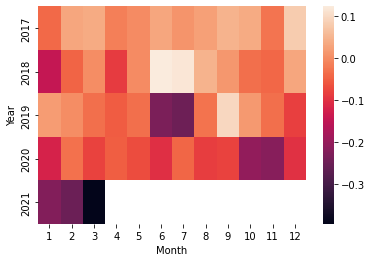

In [15]:
table_pivot_3 = pd.pivot_table(data, values='Balance', index=['Year'], columns=['Month'], aggfunc="mean")
sns.heatmap(table_pivot_3)


## 2. Добавление макроэкономических признаков

- [Значение ключевой ставки от ЦБ](https://www.cbr.ru/hd_base/keyrate/?UniDbQuery.Posted=True&UniDbQuery.From=01.01.2017&UniDbQuery.To=12.04.2024)
- [Уровень инфляции в РФ (по месяцам)](https://www.cbr.ru/hd_base/infl/?UniDbQuery.Posted=True&UniDbQuery.From=01.01.2017&UniDbQuery.To=12.04.2024)
- Логировние дней изменения ключевой ставки ЦБ 
- Выходные и даты праздников из производственного календаря 
- Дни выплат налогов для организаций
- [Денежные агрегаты М01, M02](https://www.cbr.ru/statistics/macro_itm/dkfs/#a_128613file)

In [16]:
# !pip install openpyxl -q

In [150]:
main_data = data.copy()

# stoch = pd.read_csv('stoch_proc_data_edited.csv') #курс рубля и доллара
central_bank_bid = pd.read_excel('цб_ключ.xlsx').rename({'Дата': 'date', 'Ставка': 'bid'}, axis = 1) # ключ от ЦБ с 01.2017
inflation = pd.read_excel('bid_and_inflation.xlsx').rename({'Дата': 'date', 'Инфляция, % г/г': 'inflation'}, 
                                                           axis = 1)[['date', 'inflation']]#инфляция
inflation['date'] = inflation['date'].astype(str)

new_dates = []
indexes = []
for i in range(len(inflation)): 
    if len(inflation.loc[i].date.split('.')[0]) == 1: 
        indexes.append(i)
        new_date = '0' + inflation.loc[i].date.split('.')[0] + '.' + inflation.loc[i].date.split('.')[1]
        new_dates.append(new_date)

In [151]:
inflation.loc[inflation.index.isin(indexes), 'date'] = new_dates
central_bank_bid.date = central_bank_bid.date.astype(str).apply(lambda x: x[:10])
main_data['date'] = main_data['Date'].astype(str).apply(lambda x: x[:10])

macro_factors = main_data.merge(central_bank_bid, on = 'date', how = 'left')
macro_factors['date'] = pd.to_datetime(macro_factors['date'])
macro_factors['date_str'] = macro_factors['date'].dt.strftime('%m.%Y')


macro_factors = macro_factors.merge(inflation, left_on = 'date_str', 
                                    right_on = 'date', how = 'left')

assert main_data.shape[0] == macro_factors.shape[0]

macro_factors = macro_factors[['Date','bid', 'Income', 'Outcome', 'Balance', 'Year',
       'Month', 'DayofWeek', 'DayofMonth']]

macro_factors['bid_days_change'] = np.where(macro_factors['bid'] != macro_factors['bid'].shift(), 1, 0)

macro_factors.head()

,Date,bid,Income,Outcome,Balance,Year,Month,DayofWeek,DayofMonth,bid_days_change
0,2017-01-09,10.0,1.340000,1.490000,-0.155904,2017,1,0,9,1
1,2017-01-10,10.0,1.068610,1.194182,-0.125572,2017,1,1,10,0
2,2017-01-11,10.0,0.944429,0.936663,0.007767,2017,1,2,11,0
3,2017-01-12,10.0,1.670000,0.875379,0.800391,2017,1,3,12,0
4,2017-01-13,10.0,0.955924,0.975645,-0.019721,2017,1,4,13,0


In [152]:
# macro_factors

In [153]:
monetary = pd.read_csv('agg1.csv', sep=';', header=None).transpose()
cols = monetary.loc[0, :].to_list()
cols[0] = 'date'
monetary.columns = cols
monetary = monetary.loc[1:, :].reset_index(drop=True)
monetary.head(3)


with open('mapping-3.json', encoding='utf-8') as f:
    mapping = json.load(f)
monetary.columns = [mapping[el] for el in monetary.columns]
monetary.head()


st = pd.DataFrame(monetary.isna().any(axis=0))
monetary = monetary[st[-st[0]].index]
monetary['Year'] = monetary['date'].apply(lambda x: x.split('.')[2]).astype(int)
monetary['Year'] = monetary['Year'] + 2000
monetary['Month'] = monetary['date'].apply(lambda x: x.split('.')[1]).astype(int)
all_macro_features = macro_factors.merge(monetary, on=['Year', 'Month'], how='left')

assert macro_factors.shape[0] == all_macro_features.shape[0]

In [154]:
dd = all_macro_features.copy()
dd.dropna(inplace = True)
dd['is_weekend'] = dd.DayofWeek.isin([5,6])*1

dd['Income_lag1'] = dd['Income'].shift(1)
dd['Income_lag2'] = dd['Income'].shift(2)
dd['Income_lag7'] = dd['Income'].shift(7)
dd['Income_lag5'] = dd['Income'].shift(5)

dd['Outcome_lag1'] = dd['Outcome'].shift(1)
dd['Outcome_lag2'] = dd['Outcome'].shift(2)
dd['Outcome_lag7'] = dd['Outcome'].shift(7)
dd['Outcome_lag5'] = dd['Outcome'].shift(5)


dd['Balance_lag1'] = dd['Balance'].shift(1)
dd['Balance_lag2'] = dd['Balance'].shift(2)
dd['Balance_lag7'] = dd['Balance'].shift(7)
dd['Balance_lag5'] = dd['Balance'].shift(5)


dd['tax_date'] = dd['DayofMonth'].isin([28]) * 1
dd['end_of_th_year'] = list(map(lambda x, y: 1 if x == 12 and y >= 27 else 0, dd['Month'], dd['DayofMonth']))
dd['beggining_of_th_year'] = list(map(lambda x, y: 1 if x == 1 and y <= 10 else 0, dd['Month'], dd['DayofMonth']))

dd['Income_rolling_std'] =  dd.Income.rolling(window=10).std().shift(1)
dd['Outcome_rolling_std'] =  dd.Outcome.rolling(window=10).std().shift(1)
dd['Balance_rolling_std'] =  dd.Balance.rolling(window=10).std().shift(1)

dd['Income_rolling_std_30'] =  dd.Income.rolling(window=30).std().shift(1)
dd['Outcome_rolling_std_30'] =  dd.Outcome.rolling(window=30).std().shift(1)
dd['Balance_rolling_std_30'] =  dd.Balance.rolling(window=30).std().shift(1)

dd['Income_rolling_mean'] = dd['Income'].rolling(7).mean().shift(1)
dd['Outcome_rolling_mean'] = dd['Outcome'].rolling(7).mean().shift(1)
dd['Balance_rolling_mean'] = dd['Balance'].rolling(7).mean().shift(1)


dd['Income_rolling_mean_14'] = dd['Income'].rolling(14).mean().shift(1)
dd['Outcome_rolling_mean_14'] = dd['Outcome'].rolling(14).mean().shift(1)
dd['Balance_rolling_mean_14'] = dd['Balance'].rolling(14).mean().shift(1)


dd.dropna(inplace = True)

dd.drop(columns = ['date'], inplace = True)

#тк в данных с макроэкономическими факторами есть неконсистентность в dtypes у части признаков, приводим все к читаемым 
#численным значениям
def convert_object_columns_to_float(df):
    object_columns = df.select_dtypes(include=['object']).columns
    for col in object_columns:
        if not('ate' in col):
            try:
                df[col] = df[col].str.replace(',', '.').astype(float)
            except (ValueError, AttributeError):
                print(df[col])
    return df

In [155]:
#с разными окнами считаем наклон линии тренда для основных переменных
def count_window_trend(data: pd.Series, wsize: int = 7):
    res = [0.0, 0.0, ]
    for i in range(2, len(data)):
        y = data.iloc[max(i - wsize, 0):i]
        x = np.arange(len(y))
        a = np.polyfit(x, y, deg=1)[1]
        res.append(a)
    return pd.Series(res)

In [156]:
dd_remove_dates = convert_object_columns_to_float(dd).reset_index(drop = True)

for i in range(7, 31):
    dd_remove_dates[f'income_angle_{i}'] = count_window_trend(data.Income, wsize=i)
    dd_remove_dates[f'outcome_angle_{i}'] = count_window_trend(data.Outcome, wsize=i)
    dd_remove_dates[f'balance_angle_{i}'] = count_window_trend(data.Balance, wsize=i)

In [157]:
dd_remove_dates.head(5)

,Date,bid,Income,Outcome,Balance,Year,Month,DayofWeek,DayofMonth,bid_days_change,...,balance_angle_27,income_angle_28,outcome_angle_28,balance_angle_28,income_angle_29,outcome_angle_29,balance_angle_29,income_angle_30,outcome_angle_30,balance_angle_30
0,2017-02-20,10.0,1.119653,1.144411,-0.024759,2017,2,0,20,1,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2017-02-21,10.0,1.287537,1.156468,0.131069,2017,2,1,21,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,2017-02-22,10.0,1.440000,1.420000,0.022756,2017,2,2,22,0,...,-0.155904,1.340000,1.490000,-0.155904,1.340000,1.490000,-0.155904,1.340000,1.490000,-0.155904
3,2017-02-27,10.0,1.760000,1.880000,-0.118862,2017,2,0,27,1,...,-0.173072,1.315465,1.483617,-0.173072,1.315465,1.483617,-0.173072,1.315465,1.483617,-0.173072
4,2017-02-28,10.0,1.500000,1.710000,-0.211128,2017,2,1,28,0,...,-0.318663,1.125887,1.439263,-0.318663,1.125887,1.439263,-0.318663,1.125887,1.439263,-0.318663


In [158]:
# делим на train-test-val
from datetime import date, timedelta
from sklearn.model_selection import train_test_split

def df_train_test_split(dd, start_date, target_column, columns_to_drop):

    final_df = dd.drop_duplicates().dropna()
    final_df['Month'] = final_df.Month.astype('str')
    final_df['DayofWeek'] = final_df.DayofWeek.astype('str')
    dummies_df = pd.get_dummies(final_df.loc[:, ['DayofWeek', 'Month']], prefix=['Weekday', 'Month'],
                                drop_first = True)
    for col in dummies_df.columns:
        final_df[col] = dummies_df[col]
    final_df.drop(columns = ['DayofWeek', 'Month'], inplace = True)
    
    X_val = final_df[final_df.Date.dt.date >= date.fromisoformat(start_date)].drop(columns = columns_to_drop)
    X_learn = final_df[final_df.Date.dt.date < date.fromisoformat(start_date)].drop(columns = columns_to_drop)

    y_val = final_df[final_df.Date.dt.date >= date.fromisoformat(start_date)][target_column]
    y_learn = final_df[final_df.Date.dt.date < date.fromisoformat(start_date)][target_column]

    X_train, X_test, y_train, y_test = train_test_split(X_learn, y_learn, test_size=0.33, random_state=42,
                                                        shuffle=False)
    print(X_train.shape, X_test.shape)
    
    return X_train, X_test, y_train, y_test, X_val, y_val # df_train_test_split

In [159]:
dd.columns

Index(['Date', 'bid', 'Income', 'Outcome', 'Balance', 'Year', 'Month',
       'DayofWeek', 'DayofMonth', 'bid_days_change', 'm0', 'ruble_trans_depos',
       'fin_trans_depos', 'non_fin_trans_depos', 'home_trans_depos', 'm1',
       'ruble_other_depos', 'other_fin_depos', 'non_fin_other_depos',
       'other_home_depos', 'm2', 'other_curr_depos', 'fin_curr_depos',
       'non_fin_curr_depos', 'curr_home_depos', 'wide_mass', 'is_weekend',
       'Income_lag1', 'Income_lag2', 'Income_lag7', 'Income_lag5',
       'Outcome_lag1', 'Outcome_lag2', 'Outcome_lag7', 'Outcome_lag5',
       'Balance_lag1', 'Balance_lag2', 'Balance_lag7', 'Balance_lag5',
       'tax_date', 'end_of_th_year', 'beggining_of_th_year',
       'Income_rolling_std', 'Outcome_rolling_std', 'Balance_rolling_std',
       'Income_rolling_std_30', 'Outcome_rolling_std_30',
       'Balance_rolling_std_30', 'Income_rolling_mean', 'Outcome_rolling_mean',
       'Balance_rolling_mean', 'Income_rolling_mean_14',
       'Outcome_ro

# SARIMAX

Посмотрим на модель SARIMAX для Income и Outcome, попробуем на этим моделях найти дополнительные значимые признаки.

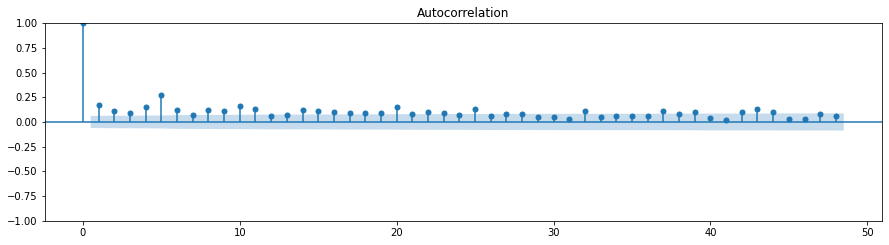

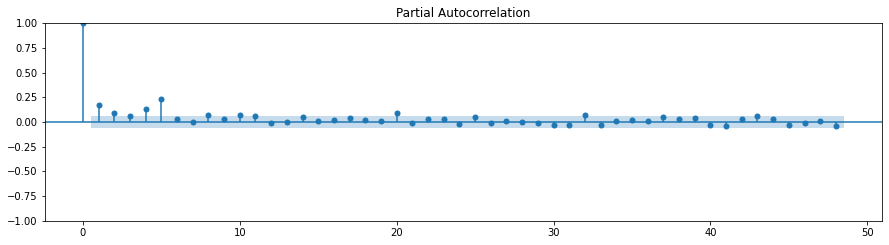

In [160]:
plt.figure(figsize = (15,8))
ax = plt.subplot(211)
sm.graphics.tsa.plot_acf(dd.Balance.values.squeeze(), lags=48, ax=ax)
plt.show()
plt.figure(figsize = (15,8))
ax = plt.subplot(212)
sm.graphics.tsa.plot_pacf(dd.Balance.values.squeeze(), lags=48, ax=ax)
plt.show()

Критерий Дики-Фуллера: p=0.000030


<Figure size 1080x720 with 0 Axes>

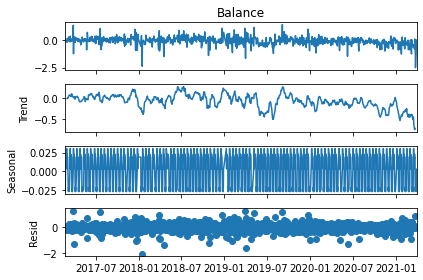

In [161]:
dd['Date'] = pd.to_datetime(dd['Date'])
idx = pd.DatetimeIndex(dd['Date'])

dd.set_index(idx, drop = False, inplace= True)
dd.sort_index(inplace=True)
plt.figure(figsize = (15,10))
sm.tsa.seasonal_decompose(dd.Balance, period = 10).plot()
print("Критерий Дики-Фуллера: p=%f" % sm.tsa.stattools.adfuller(dd.Balance)[1])

In [163]:
ps = range(1, 6)
d=1
qs = range(0, 3)
Ps = range(0, 2)
D=1
Qs = range(0, 2)

from itertools import product

parameters = product(ps, qs, Ps, Qs)
parameters_list = list(parameters)
len(parameters_list)

60

In [164]:
results = []
best_aic = float("inf")
warnings.filterwarnings('ignore')

for param in parameters_list:
    #try except нужен, потому что на некоторых наборах параметров модель не обучается
    try:
        
        model_sm=sm.tsa.statespace.SARIMAX(dd.Balance, order=(param[0], d, param[1]), 
                                        seasonal_order=(param[2], D, param[3], 12)).fit(disp=-1)
        
    #выводим параметры, на которых модель не обучается и переходим к следующему набору
    except ValueError:
        print('wrong parameters:', param)
        continue
    aic = model_sm.aic
    
    #сохраняем лучшую модель, aic, параметры
    if aic < best_aic:
        best_model = model_sm
        best_aic = aic
        best_param = param
    results.append([param, model_sm.aic])
    
warnings.filterwarnings('default')

result_table = pd.DataFrame(results)
result_table.columns = ['parameters', 'aic']
print(result_table.sort_values(by = 'aic', ascending=True).head())

      parameters         aic
53  (5, 1, 0, 1)  703.833207
55  (5, 1, 1, 1)  703.921627
59  (5, 2, 1, 1)  706.025395
57  (5, 2, 0, 1)  706.872045
47  (4, 2, 1, 1)  727.518000


In [165]:
result_table = pd.DataFrame(results)
result_table.columns = ['parameters', 'aic']
print(result_table.sort_values(by = 'aic', ascending=True).head()) 

      parameters         aic
53  (5, 1, 0, 1)  703.833207
55  (5, 1, 1, 1)  703.921627
59  (5, 2, 1, 1)  706.025395
57  (5, 2, 0, 1)  706.872045
47  (4, 2, 1, 1)  727.518000


In [166]:
print(best_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                            Balance   No. Observations:                 1023
Model:             SARIMAX(5, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -343.917
Date:                            Sun, 14 Apr 2024   AIC                            703.833
Time:                                    22:22:26   BIC                            743.175
Sample:                                         0   HQIC                           718.779
                                           - 1023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0528      0.031      1.676      0.094      -0.009       0.115
ar.L2          0.0041      0.035   

Критерий Стьюдента: p=0.358864
Критерий Дики-Фуллера: p=0.000000


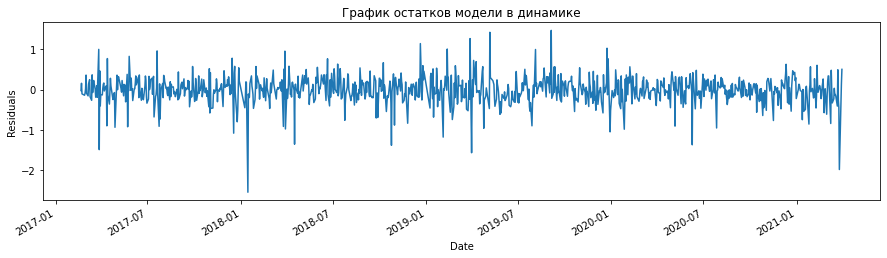

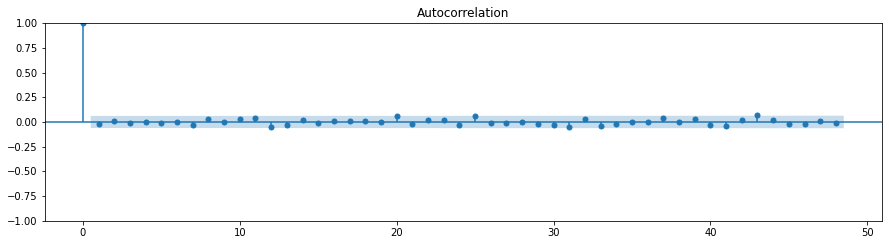

In [167]:
from scipy import stats

plt.figure(figsize = (15,8))
plt.subplot(211)
plt.title('График остатков модели в динамике')
best_model.resid.plot()
plt.ylabel(u'Residuals')
plt.figure(figsize = (15,8))
ax = plt.subplot(212)
sm.graphics.tsa.plot_acf(best_model.resid.values.squeeze(), lags=48, ax=ax)

print("Критерий Стьюдента: p=%f" % stats.ttest_1samp(best_model.resid[13:], 0)[1])
print("Критерий Дики-Фуллера: p=%f" % sm.tsa.stattools.adfuller(best_model.resid[13:])[1])

Видим, что нулевая гипотеза о равенстве среднего остатков нулю не отвергается с p-value = 0.814066, то есть у нас нет однонаправленного смещения в остатках модели. 

Попробуем добавить в модель экзогенные факторы, которые мы собирали выше: 

In [168]:
from sklearn.metrics import mean_absolute_error

X_train, X_test, y_train, y_test, X_val, y_val  = df_train_test_split(dd.drop(columns = [
       'Balance_lag1', 'Balance_lag2', 'Balance_lag5']), start_date = '2020-03-01', 
                                   target_column = 'Balance', 
                                   columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance'])
# (2, 1, 0, 1)
model_sm_new_2=sm.tsa.statespace.SARIMAX(y_train, exog = X_train, order=(2, 1, 1), 
                                        seasonal_order=(0, 1, 1, 12)).fit(disp=-1)
        
aic = model_sm_new_2.aic
y_train_preds_2 = model_sm_new_2.predict(exog = X_train)

print(f'Model AIC = {aic}')
print(f'MAE on train: {mean_absolute_error(y_train, y_train_preds_2)}')

(502, 61) (248, 61)


/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings

Model AIC = 561.7493594184016
MAE on train: 6.580733706248278


MAE on train: 6.58 - достаточно большая ошибка на трейне по сравнению с другими бейзлайнами, которые мы пробуем дальше

In [169]:
print(model_sm_new_2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                            Balance   No. Observations:                  502
Model:             SARIMAX(2, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -214.875
Date:                            Sun, 14 Apr 2024   AIC                            561.749
Time:                                    22:23:02   BIC                            838.445
Sample:                                         0   HQIC                           670.427
                                            - 502                                         
Covariance Type:                              opg                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
bid                         0.8335      0.342      2.439      0.015       0.164       1.

Качество модели улучшилось, но интересно, что значимыми фичами оказались по сути только день месяца (DayofMonth) и флаг конца года (end_of_th_year), а остальные фичи остались незначимыми 

Критерий Стьюдента: p=0.863578
Критерий Дики-Фуллера: p=0.000000


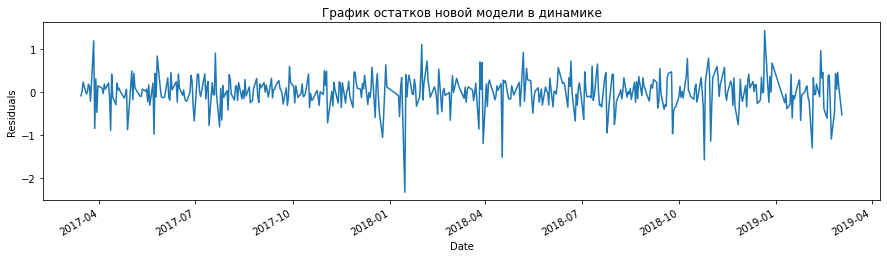

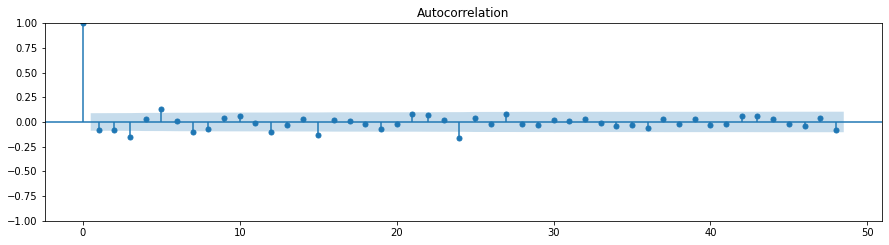

In [170]:
plt.figure(figsize = (15,8))
plt.subplot(211)
model_sm_new_2.resid[14:].plot()
plt.ylabel(u'Residuals')
plt.title('График остатков новой модели в динамике')
plt.figure(figsize = (15,8))
ax = plt.subplot(212)
sm.graphics.tsa.plot_acf(model_sm_new_2.resid[14:].values.squeeze(), lags=48, ax=ax)

print("Критерий Стьюдента: p=%f" % stats.ttest_1samp(model_sm_new_2.resid[14:], 0)[1])
print("Критерий Дики-Фуллера: p=%f" % sm.tsa.stattools.adfuller(model_sm_new_2.resid[14:])[1])

<Axes: >

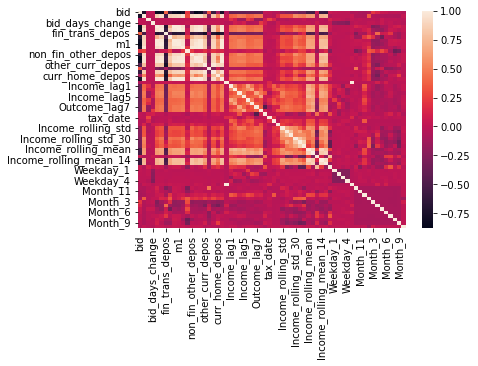

In [171]:
X_train_1 = X_train.copy()
X_train_1['sarimax_resids'] = model_sm_new_2.resid
c = X_train_1.corr()
sns.heatmap(c)

## Обучение ML бейзлайнов 

**Глобальная идея:** 

Поскольку метрики на SARIMAX нас не очень устроили, для выбора основной модели для нашей задачи мы решили рассмотреть несколько ML бейзлайнов - LinearRegression, GradientBoostingRegressor, DecisionTreeRegressor, AdaBoostRegressor. 

Для каждого из бейзлайнов подбираются наилучшие параметры с помощью GridSearchCV, далее кандидат с лучшими параметрами фитится на основных данных, и выводятся метрики качества по предсказаниям и реальным значениям теста. В качестве метрики качества модели мы мониторим МАЕ. 

Лучшие модели сохраняются для доступного импорта в других частях пайплайна. 


In [41]:
class ModelTrainer:
    def __init__(self, df, y_col):
    
        self.df = df
        self.y_col = y_col
        self.X = self.df.drop(columns=[y_col])
        self.X['constant'] = 1
        self.y = self.df[y_col]
        # (dd = self.df, start_date = '2020-03-01', target_column = y_col, columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance']):
        self.X_train, self.X_test, self.y_train, self.y_test, self.X_val, self.y_val = df_train_test_split(dd = self.df, 
                start_date = '2020-03-01', target_column = y_col, columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance'])


    def train_and_plot_models(self):
        models = [
            (LinearRegression(), 'Linear Regression', None),
            
            (GradientBoostingRegressor(random_state=42), 'Gradient Boosting Regressor', {
                'learning_rate': [0.01,0.02,0.03,0.04,0.05,0.07],
                'subsample': [0.9, 0.5, 0.2, 0.1],
                'n_estimators': [100,500,1000,1500],
                'max_depth': [4,6,8,10]
            }),
            (DecisionTreeRegressor(random_state=42), 'Decision Tree Regressor', {
                "splitter":["best","random"],
                "max_depth" : [1,5,7,9],
                "min_samples_leaf":[1,2,3,4,5],
                "min_weight_fraction_leaf":[0.1,0.2,0.3,0.4,0.5],
                "max_features":["log2","sqrt",None],
                "max_leaf_nodes":[None,10,20,30]
            }),
            (AdaBoostRegressor(random_state=42), 'Ada Boost Regressor', {
                'n_estimators':[500,1000,2000],
                'learning_rate':[.001,0.01,.1]
            })
        ]

        for model, model_name, param_grid in models:
            self.train_and_plot(model, model_name, param_grid)

    def train_and_plot(self, model, model_name, param_grid=None):
        if param_grid:
            grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=2, n_jobs=-1)
            grid_search.fit(self.X_train, self.y_train)
            print(f"Results from Grid Search for {model_name}")
            print("\n The best estimator across ALL searched params:\n", grid_search.best_estimator_)
            print("\n The best score across ALL searched params:\n", grid_search.best_score_)
            print("\n The best parameters across ALL searched params:\n", grid_search.best_params_)
            model = type(model)(**grid_search.best_params_)

        model.fit(self.X_train, self.y_train)
        prediction = model.predict(self.X_test)
        self.plot_results(prediction, model_name)
        
        dump(model, f'{model_name}_{self.y_col}.joblib')

    def plot_results(self, prediction, model_name):
        plt.figure(figsize=(15, 7))
        plt.plot(prediction, "r", label="prediction")
        plt.plot(self.y_test.values, label="actual")
        plt.legend(loc="best")
        plt.title(f"{model_name}\n Mean absolute error = {round(mean_absolute_error(prediction, self.y_test), 3)}")
        plt.grid(True)

(502, 136) (248, 136)
Results from Grid Search for Gradient Boosting Regressor

 The best estimator across ALL searched params:
 GradientBoostingRegressor(learning_rate=0.04, max_depth=8, random_state=42,
                          subsample=0.1)

 The best score across ALL searched params:
 0.035795973024886574

 The best parameters across ALL searched params:
 {'learning_rate': 0.04, 'max_depth': 8, 'n_estimators': 100, 'subsample': 0.1}


/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:547: FitFailedWarning: 
1600 fits failed out of a total of 6400.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
948 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 895, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 1467, in wrapper
    estimator._validate_params()
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 666, in _validate_p

Results from Grid Search for Decision Tree Regressor

 The best estimator across ALL searched params:
 DecisionTreeRegressor(max_depth=5, max_leaf_nodes=10,
                      min_weight_fraction_leaf=0.2, random_state=42)

 The best score across ALL searched params:
 -0.11647674371825945

 The best parameters across ALL searched params:
 {'max_depth': 5, 'max_features': None, 'max_leaf_nodes': 10, 'min_samples_leaf': 1, 'min_weight_fraction_leaf': 0.2, 'splitter': 'best'}
Results from Grid Search for Ada Boost Regressor

 The best estimator across ALL searched params:
 AdaBoostRegressor(learning_rate=0.1, n_estimators=2000, random_state=42)

 The best score across ALL searched params:
 -0.04603174840071633

 The best parameters across ALL searched params:
 {'learning_rate': 0.1, 'n_estimators': 2000}


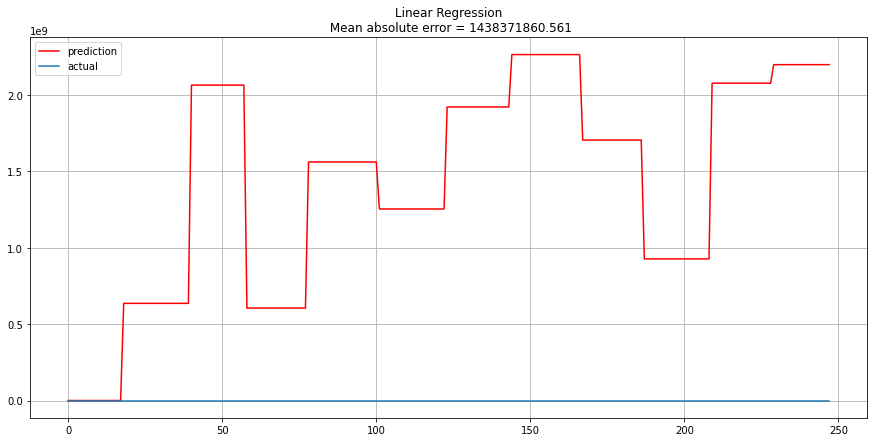

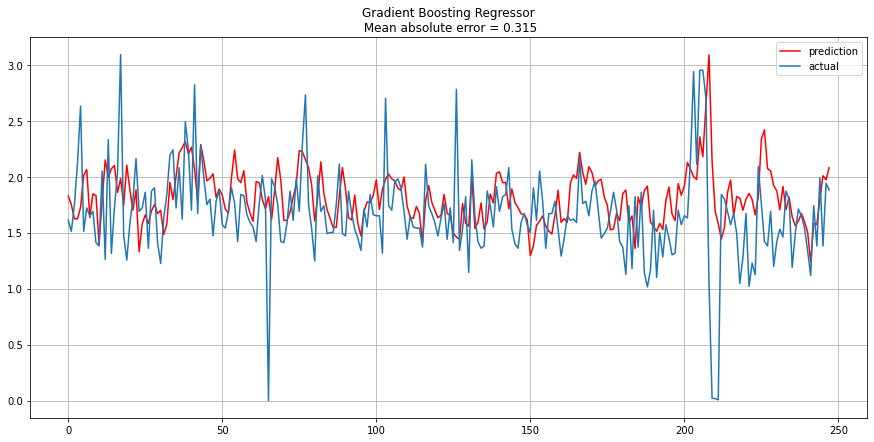

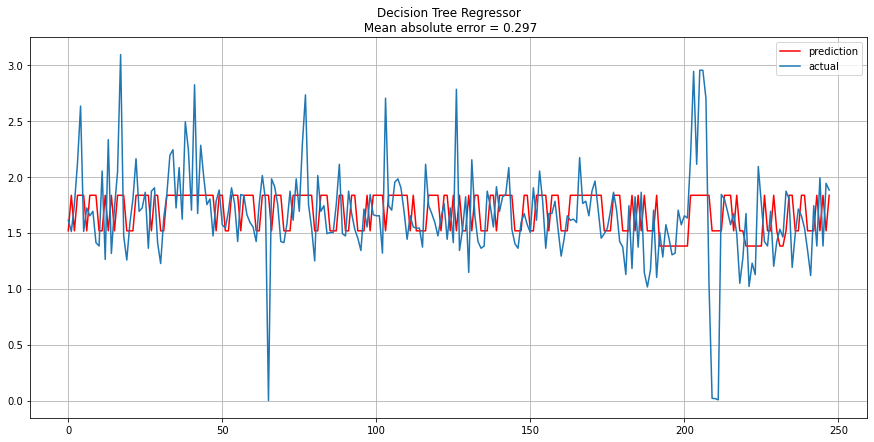

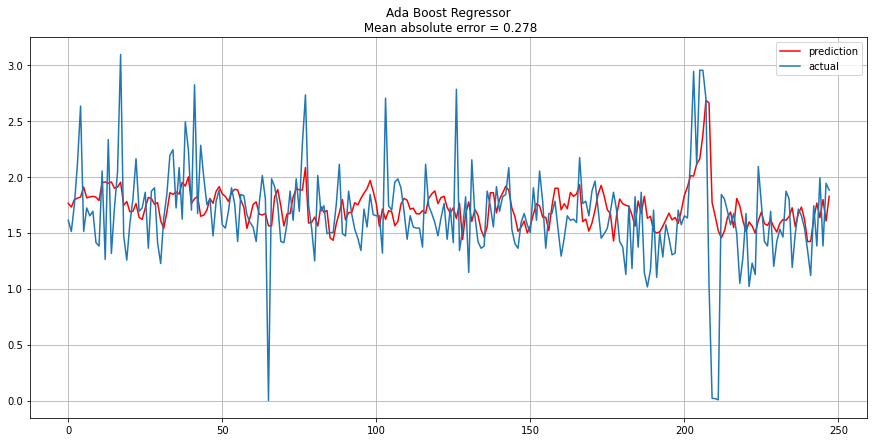

In [42]:
trainer = ModelTrainer(dd_remove_dates, 'Income')
trainer.train_and_plot_models()

## Модель для Outcome 

(502, 136) (248, 136)
Results from Grid Search for Gradient Boosting Regressor

 The best estimator across ALL searched params:
 GradientBoostingRegressor(learning_rate=0.01, max_depth=8, random_state=42,
                          subsample=0.2)

 The best score across ALL searched params:
 -0.09352603556697592

 The best parameters across ALL searched params:
 {'learning_rate': 0.01, 'max_depth': 8, 'n_estimators': 100, 'subsample': 0.2}


/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:547: FitFailedWarning: 
1600 fits failed out of a total of 6400.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1232 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 895, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 1467, in wrapper
    estimator._validate_params()
  File "/Users/a.bogoslavskaya/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 666, in _validate_

Results from Grid Search for Decision Tree Regressor

 The best estimator across ALL searched params:
 DecisionTreeRegressor(max_depth=5, max_leaf_nodes=10,
                      min_weight_fraction_leaf=0.1, random_state=42)

 The best score across ALL searched params:
 0.007356483061476626

 The best parameters across ALL searched params:
 {'max_depth': 5, 'max_features': None, 'max_leaf_nodes': 10, 'min_samples_leaf': 1, 'min_weight_fraction_leaf': 0.1, 'splitter': 'best'}
Results from Grid Search for Ada Boost Regressor

 The best estimator across ALL searched params:
 AdaBoostRegressor(learning_rate=0.1, n_estimators=1000, random_state=42)

 The best score across ALL searched params:
 0.02785597859919159

 The best parameters across ALL searched params:
 {'learning_rate': 0.1, 'n_estimators': 1000}


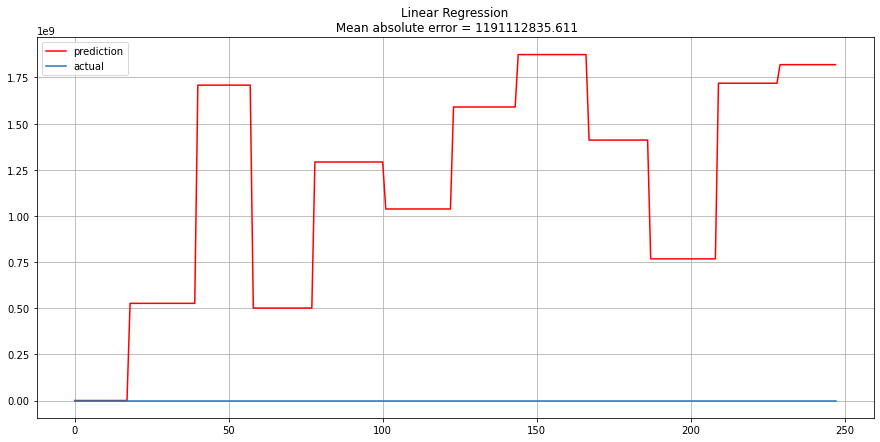

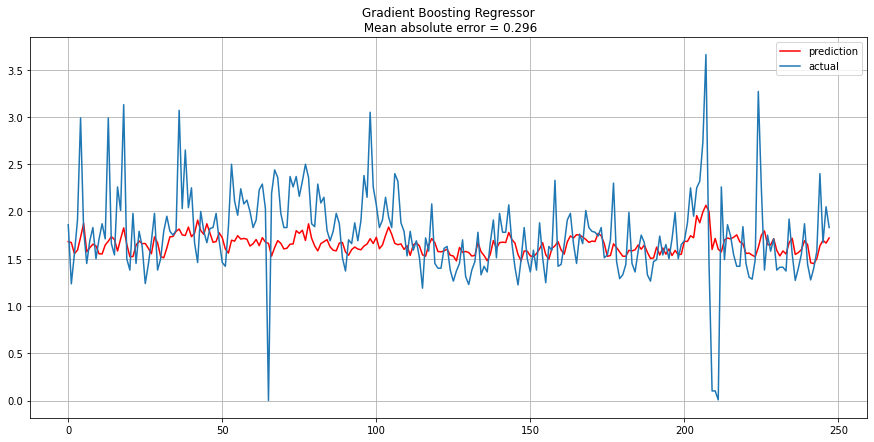

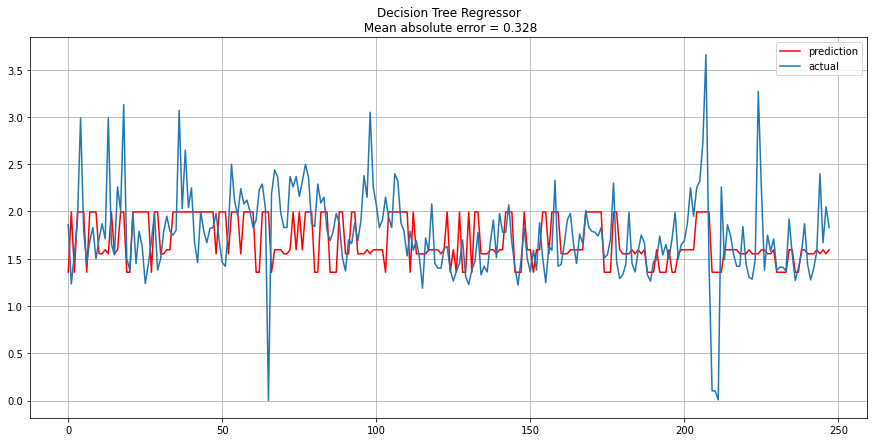

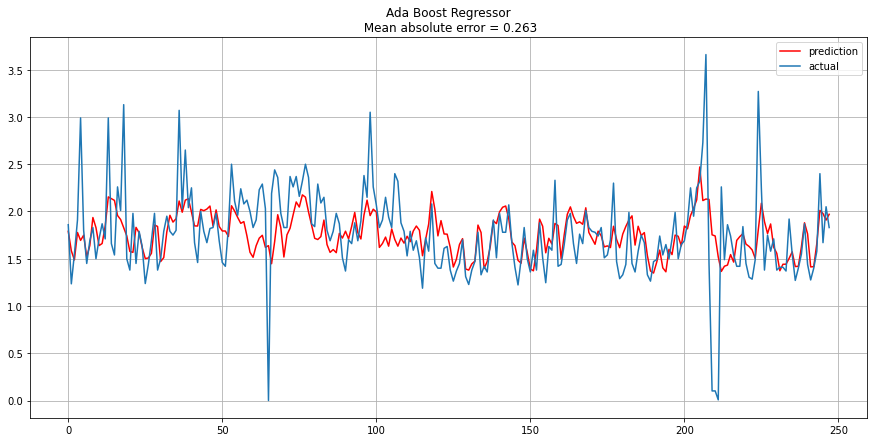

In [43]:
trainer = ModelTrainer(dd_remove_dates, 'Outcome')
trainer.train_and_plot_models()

## Модель для Balance 

Для обеих метрик Income и Outcome наилучшими оказываются модели бустинга с метриками MAE < 0.28: 

- **'Income'**: 
    - AdaBoostRegressor(learning_rate=0.1, n_estimators=2000, random_state=42)
    - МAE = 0.278
- **'Outcome'**: 
    - AdaBoostRegressor(learning_rate=0.1, n_estimators=1000, random_state=42)
    - MAE - 0.263


**Хотим попробовать несколько стратегий для того,чтобы построить модель для Баланса:**                        
1. AdaBoostRegressor + подбор параметров для модели Balance из ModelTrainer()
2. Balance как diff предсказания Income и Outcome моделей с MSE ф-ии потерь                  

In [50]:
X_train, X_test, y_train, y_test, X_val, y_val  = df_train_test_split(dd_remove_dates, start_date = '2020-03-01', 
                                   target_column = 'Balance', 
                                   columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance'])

(502, 136) (248, 136)


In [59]:
model_balance = AdaBoostRegressor(random_state = 42)

params = { 'n_estimators':[500,1000,2000],
          'learning_rate':[.001,0.01,.1]
         }

grid_search = GridSearchCV(estimator=model_balance, param_grid=params, cv=2, n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Results from Grid Search for AdaBoostRegressor")
print("\n The best estimator across ALL searched params:\n", grid_search.best_estimator_)
print("\n The best score across ALL searched params:\n", grid_search.best_score_)
print("\n The best parameters across ALL searched params:\n", grid_search.best_params_)

Results from Grid Search for AdaBoostRegressor

 The best estimator across ALL searched params:
 AdaBoostRegressor(learning_rate=0.01, n_estimators=1000, random_state=42)

 The best score across ALL searched params:
 0.003516474402106007

 The best parameters across ALL searched params:
 {'learning_rate': 0.01, 'n_estimators': 1000}


In [96]:
model_balance_abg = AdaBoostRegressor(learning_rate=0.1, n_estimators=2000, random_state=42)
model_balance_abg.fit(X_train, y_train)

AdaBoostRegressor(learning_rate=0.1, n_estimators=2000, random_state=42)

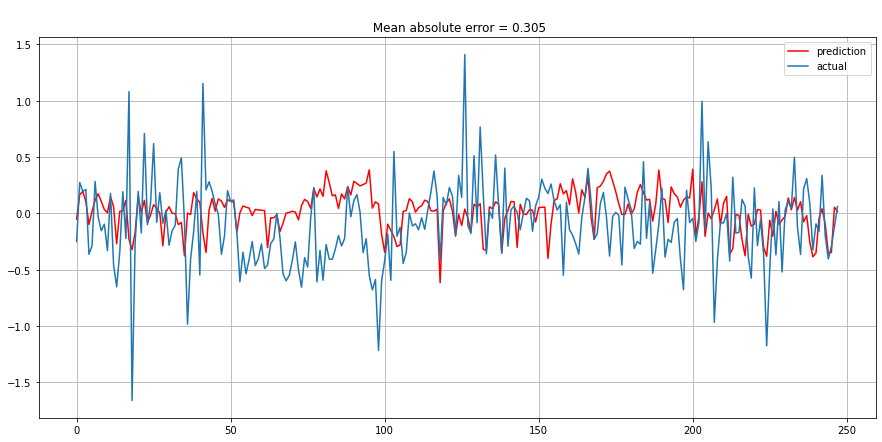

In [97]:
prediction = model_balance_abg.predict(X_test)

plt.figure(figsize=(15, 7))
plt.plot(prediction, "r", label="prediction")
plt.plot(y_test.values, label="actual")
plt.legend(loc="best")
plt.title(f"\n Mean absolute error = {round(mean_absolute_error(prediction, y_test), 3)}")
plt.grid(True)

In [54]:
model_balance = GradientBoostingRegressor(loss = 'quantile', alpha=0.25, random_state = 42)

params = {'learning_rate': [0.01,0.02,0.03],
                'subsample': [0.9, 0.5, 0.2, 0.1],
                'n_estimators': [100,500,1000],
                'max_depth': [4,6,8,10]
         }

grid_search = GridSearchCV(estimator=model_balance, param_grid=params, cv=2, n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Results from Grid Search for GradientBoostingRegressor")
print("\n The best estimator across ALL searched params:\n", grid_search.best_estimator_)
print("\n The best score across ALL searched params:\n", grid_search.best_score_)
print("\n The best parameters across ALL searched params:\n", grid_search.best_params_)

Results from Grid Search for GradientBoostingRegressor

 The best estimator across ALL searched params:
 GradientBoostingRegressor(alpha=0.25, learning_rate=0.01, loss='quantile',
                          max_depth=4, random_state=42, subsample=0.1)

 The best score across ALL searched params:
 -0.2924803496795759

 The best parameters across ALL searched params:
 {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 100, 'subsample': 0.1}


In [55]:
model_balance_gbr = GradientBoostingRegressor(alpha=0.25, learning_rate=0.01, loss='quantile',
                          max_depth=4, random_state=42, subsample=0.1)
model_balance_gbr.fit(X_train, y_train)

GradientBoostingRegressor(alpha=0.25, learning_rate=0.01, loss='quantile',
                          max_depth=4, random_state=42, subsample=0.1)

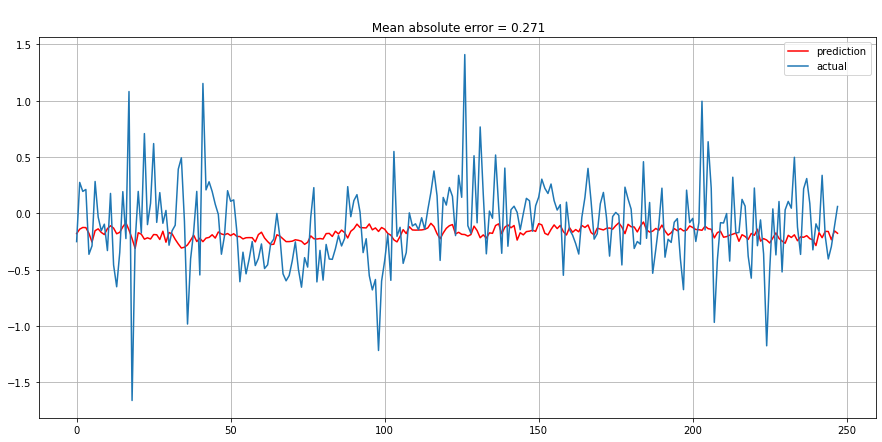

In [56]:
prediction = model_balance_gbr.predict(X_test)

plt.figure(figsize=(15, 7))
plt.plot(prediction, "r", label="prediction")
plt.plot(y_test.values, label="actual")
plt.legend(loc="best")
plt.title(f"\n Mean absolute error = {round(mean_absolute_error(prediction, y_test), 3)}")
plt.grid(True)

#ну нет......

In [57]:
from joblib import load

#проверяем гипотезу с предсказанием баланса как диффа income и outcome

model_income = load('Ada Boost Regressor_Income.joblib')
model_outcome = load('Ada Boost Regressor_Outcome.joblib')

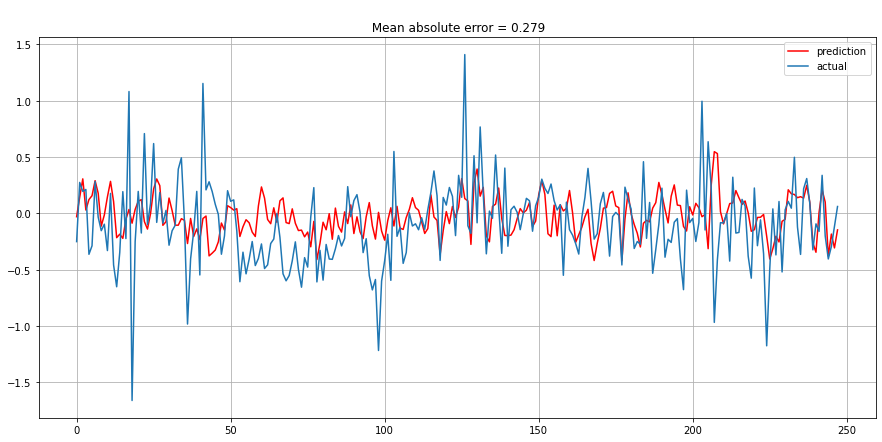

In [58]:
incom_pred = model_income.predict(X_test)
outcome_pred = model_outcome.predict(X_test)

balance_scores = incom_pred - outcome_pred

plt.figure(figsize=(15, 7))
plt.plot(balance_scores, "r", label="prediction")
plt.plot(y_test.values, label="actual")
plt.legend(loc="best")
plt.title(f"\n Mean absolute error = {round(mean_absolute_error(balance_scores, y_test), 3)}")
plt.grid(True)

#выглядит даже неплохо, но есть перекос в сторону положительного предикта - потенциально опасно тк будем занижать 
#экономические показатели бизнес метрики (вовремя не возьмем в долг, когда это нужно будет) - не самый лучший
#вариант архитектуры

# Feature selection (feature importance)

In [112]:
important_features_agb_balance = pd.Series(model_balance_abg.feature_importances_, index=X_test.columns).sort_values(ascending=False)

n = 50 #топ-25 фичей
significant_features = important_features_agb_balance.head(n).index.tolist()

In [114]:
# significant_features
#потенциально фичи, которые важны для каждой из моделей можно использовать далее

Text(0.5, 1.0, 'Feature Importance')

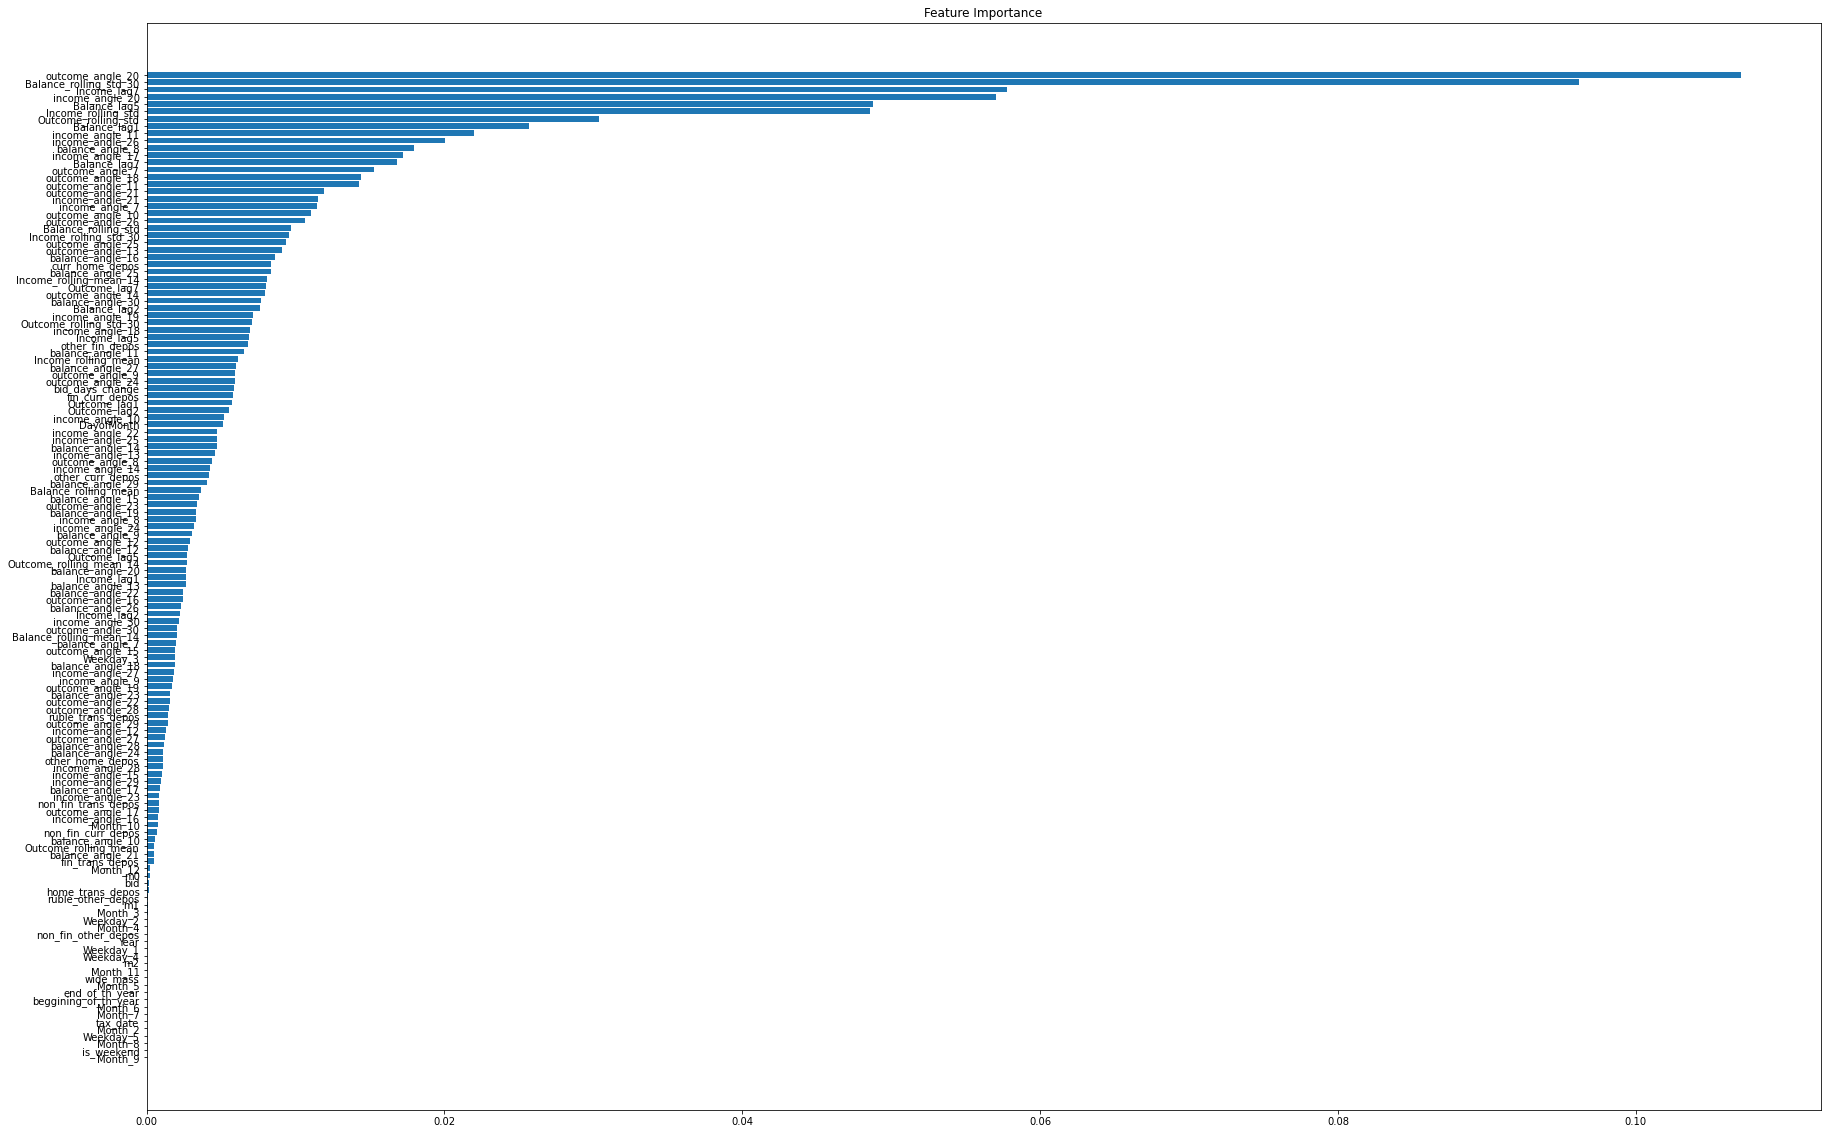

In [115]:
feature_importance = model_balance_abg.feature_importances_
sorted_idx = np.argsort(feature_importance)
fig = plt.figure(figsize=(30, 20))
plt.barh(range(len(sorted_idx)), feature_importance[sorted_idx], align='center')
plt.yticks(range(len(sorted_idx)), np.array(X_test.columns)[sorted_idx])
plt.title('Feature Importance')

In [104]:
X_train, X_test, y_train, y_test, X_val, y_val  = df_train_test_split(dd_remove_dates, start_date = '2020-03-01', 
                                   target_column = 'Balance', 
                                   columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance'])
X_train.head()

(502, 136) (248, 136)


,bid,Year,DayofMonth,bid_days_change,m0,ruble_trans_depos,fin_trans_depos,non_fin_trans_depos,home_trans_depos,m1,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,10.0,2017,20,1,7543.7,9781.8,621.2,5767.2,3393.4,17325.5,...,0,0,1,0,0,0,0,0,0,0
1,10.0,2017,21,0,7543.7,9781.8,621.2,5767.2,3393.4,17325.5,...,0,0,1,0,0,0,0,0,0,0
2,10.0,2017,22,0,7543.7,9781.8,621.2,5767.2,3393.4,17325.5,...,0,0,1,0,0,0,0,0,0,0
3,10.0,2017,27,1,7543.7,9781.8,621.2,5767.2,3393.4,17325.5,...,0,0,1,0,0,0,0,0,0,0
4,10.0,2017,28,0,7543.7,9781.8,621.2,5767.2,3393.4,17325.5,...,0,0,1,0,0,0,0,0,0,0


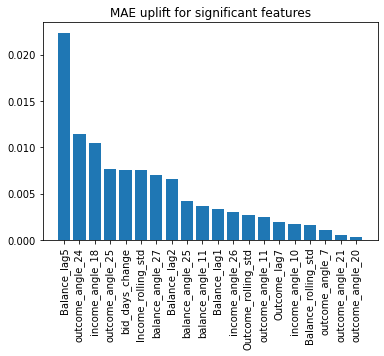

4            Balance_lag5
42       outcome_angle_24
35        income_angle_18
23       outcome_angle_25
43        bid_days_change
5      Income_rolling_std
40       balance_angle_27
32           Balance_lag2
27       balance_angle_25
38       balance_angle_11
7            Balance_lag1
9         income_angle_26
6     Outcome_rolling_std
15       outcome_angle_11
29           Outcome_lag7
47        income_angle_10
21    Balance_rolling_std
13        outcome_angle_7
16       outcome_angle_21
0        outcome_angle_20
Name: feature, dtype: object

In [116]:
d ={}

def calc_feature_importance(significant_features, X_train, y_train, X_test, y_test, model_income):
    for feature in significant_features:
        assert all(X_test.columns == X_train.columns)
        clf1 = model_income
        clf1.fit(X_train, y_train)
        a1 = mean_absolute_error(y_test, clf1.predict(X_test))
        
        clf2 = model_income
        clf2.fit(X_train.drop(columns = [feature]), y_train)
        
        a2 = mean_absolute_error(y_test, clf2.predict(X_test.drop(columns = [feature])))
        d[feature] = a2 - a1

    d_ = pd.DataFrame(columns = ['feature', 'mae_uplift'])
    for item in d.keys():
        new_line = {'feature': item, 'mae_uplift': d[item]}
        d_= d_._append(new_line, ignore_index = True)
        
    d_ = d_[d_.mae_uplift > 0].sort_values(by='mae_uplift', ascending = False)


    plt.figure()
    plt.bar(d_.feature, height=d_.mae_uplift)
    plt.title('MAE uplift for significant features')
    plt.xticks(fontsize = 10, rotation='vertical')
    plt.show()
    return d_.feature

calc_feature_importance(significant_features, X_train, y_train, X_test, y_test, model_balance)

**Комментарий:**
- выбор модели бустинга в кач-ве основной позволяет нам не так сильно переживать за выбор оптимальных фичей
- однако тут видно, что в топ попадают как раз признаки, влияние которых +- можно содержательно интерпритировать: баланс напрямую зависит от income и outcome, стат. значимых лагов и дней изменения ключа

## Бизнес логика

Далее попробуем посчитать бизнес метрику для наших предиктов. 

Мы затестили ее как для основной модели баланса (AdaBoostRegression) так и для варианта, когда предикты баланса = дифф между предиктами income и outcome (интереса ради). 

Метрики для модели, обученной на балансе напрямую, получаются адекватными для всех срезов данных (Test, Train, Val). Для модели представляющей из себя дифф между двумя моделями - на трейне и тесте значения еще сопоставимы, но на валидационном сплите начинаются расходиться. 


In [66]:
def business_metrics(balance_prediction, balance_actual, cur_rate: float):
    '''
    balance_prediction - предсказание, сделанное для сегодняшнего дня (с сегодняшнего утра на сегодняшний вечер)
    balance_actual - реализация для сегодняшнего дня (что узнаем вечером)
    cur_rate - текущая ставка 

    Возвращаем daily_income - сколько заработали (или потратили) в день
    Его нужно сложить со всеми предыдущими значениями в процессе обучения
    '''
    profit_overnight = (cur_rate - 0.9)/365 # for example (10%-0.9%) / 365 = 9.1%/365 = 0.02493150684931507 % per day
    defit_overnight = (cur_rate + 1) /365
    derivatives_rate = (cur_rate + 0.5) /365
    
    # исходим из логики, что в течение дня мы никак не можем удовлетворить тот минус на балансе, который мы предиктим
    # то есть наша логика в том, что если мы предиктим -2 на балансе к концу дня, то мы к концу дня займем деньги,
    # а больше их никуда тратить не будем (нет доп излишка, который бы разместили в деривативах)

    # то есть наказание за низкий (тем более отрицательный) прогноз - отсутствие процента за размещение в деривативах

    # при этом если мы предиктили -2, а в конце дня получили -3, 
            #то мы будем занимать 3 на overnoght, а не разницу предсказанного и реального
    # в этом смысле наша метрика правдоподобна, так как учитывает реальный бизнес-цикл, а не только качество нашей модели

    ## моделируем утро
    daily_income = 0
    if balance_prediction > 0:
        daily_income += balance_prediction * (1 + derivatives_rate)

    ## моделируем вечер, уже знаем balance_actual
    if balance_actual + daily_income < 0: ## (balance_actual - balance_prediction < 0) and (
        ## мы в состоянии дефицита: предиктили больше, чем получили в итоге
        daily_income += (balance_actual + daily_income)  * (1 + defit_overnight)
    elif balance_actual + daily_income > 0: 
        ## мы в состоянии профицита: предиктили столько или меньше, чем получили в итоге
        daily_income += (balance_actual + daily_income) * (1 + profit_overnight)

    return daily_income

In [63]:
X_train, X_test, y_train_bal, y_test_bal, X_val, y_val_bal  = df_train_test_split(dd_remove_dates, start_date = '2020-03-01', 
                                   target_column = 'Balance', 
                                   columns_to_drop = ['Date', 'Income', 'Outcome', 'Balance'])

(502, 136) (248, 136)


In [205]:
# !pip install --upgrade scikit-learn

In [85]:
def calc_business_metric_agb(X, y):
    '''
    
    Ф-ия для предикта целевой бизнес метрики для основной модели - 
    AgaBoostRegression, обученная на значениях баланса. 
    
    '''
    
    incomes_list = []
    balance_prediction = model_balance_abg.predict(X)
    
    X.reset_index(drop = True, inplace = True)
    y.reset_index(drop = True, inplace = True)

    for row_ in range(len(X)):
        balance_prediction_i = balance_prediction[row_]
        balance_actual = y[row_]
        cur_bid = X.loc[row_, 'bid']
        cur_income = business_metrics(balance_prediction_i, balance_actual, cur_bid)
        incomes_list.append(cur_income)
    print(sum(incomes_list))
    plt.figure(figsize = (15,8))
    plt.plot(incomes_list)
    plt.show()

75.65934449954678


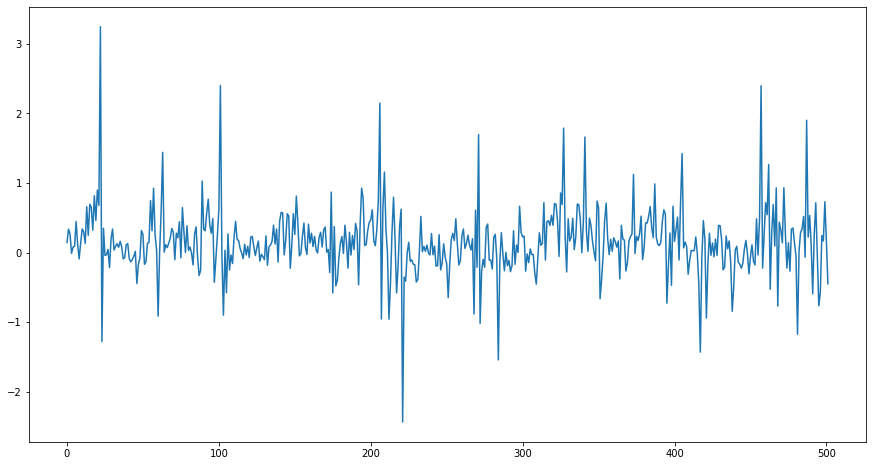

In [86]:
calc_business_metric(X_train, y_train)

13.97827489659046


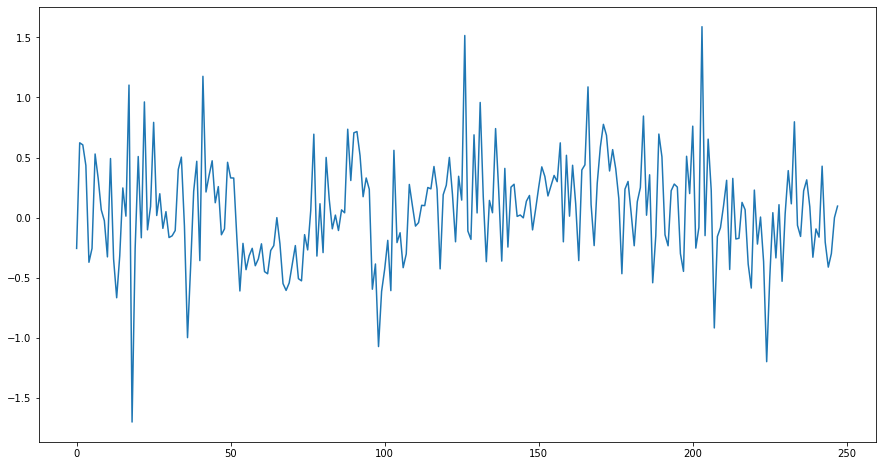

In [87]:
calc_business_metric(X_test, y_test)

-0.9722253199153328


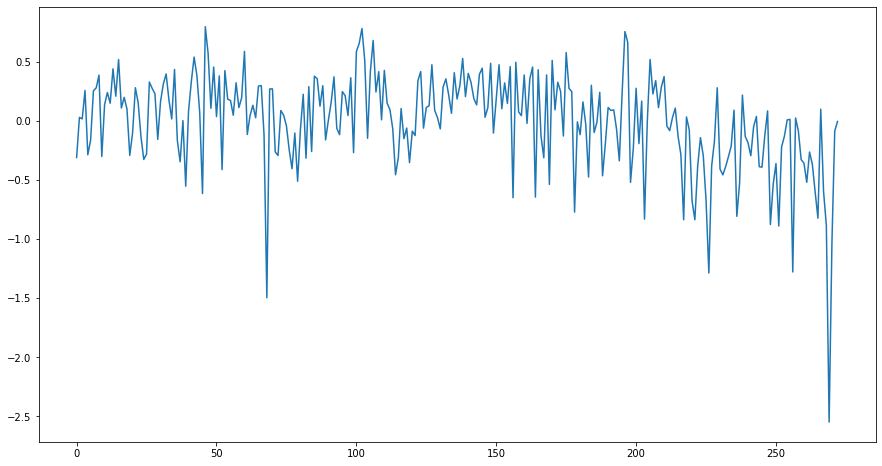

In [88]:
calc_business_metric(X_val, y_val)

In [91]:
def calc_business_metric_diff(X, y):
    '''
    
    Ф-ия для предикта целевой бизнес метрики для предсказаний баланса как диффа предсказаний моделей 
    AgaBoostRegression для Income и Outcome 
    
    '''

    incomes_list = []
    
    prediction_income = model_income.predict(X)
    prediction_outcome = model_outcome.predict(X)
    balance_prediction = prediction_income - prediction_outcome

    
    X.reset_index(drop = True, inplace = True)
    y.reset_index(drop = True, inplace = True)

    for row_ in range(len(X)):
        balance_prediction_i = balance_prediction[row_]
        balance_actual = y[row_]
        cur_bid = X.loc[row_, 'bid']
        cur_income = business_metrics(balance_prediction_i, balance_actual, cur_bid)
        incomes_list.append(cur_income)
    print(sum(incomes_list))
    plt.figure(figsize = (15,8))
    plt.plot(incomes_list)
    plt.show()

73.93523439695744


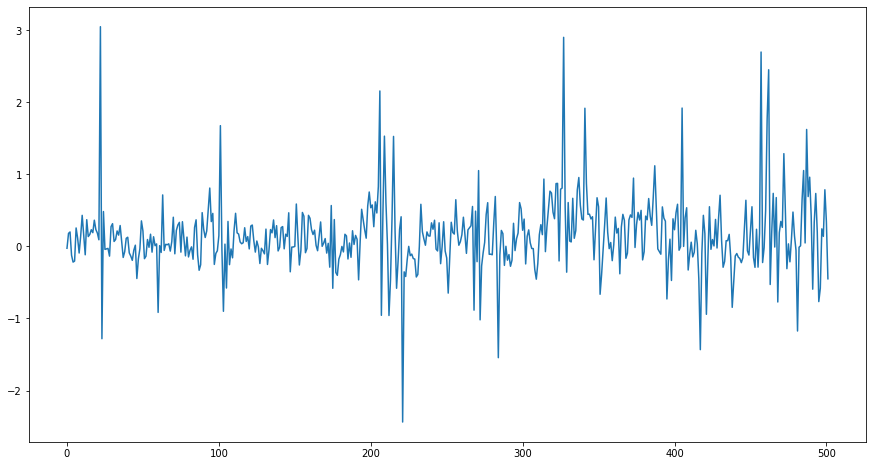

In [92]:
calc_business_metric_diff(X_train, y_train)

4.0005205432696185


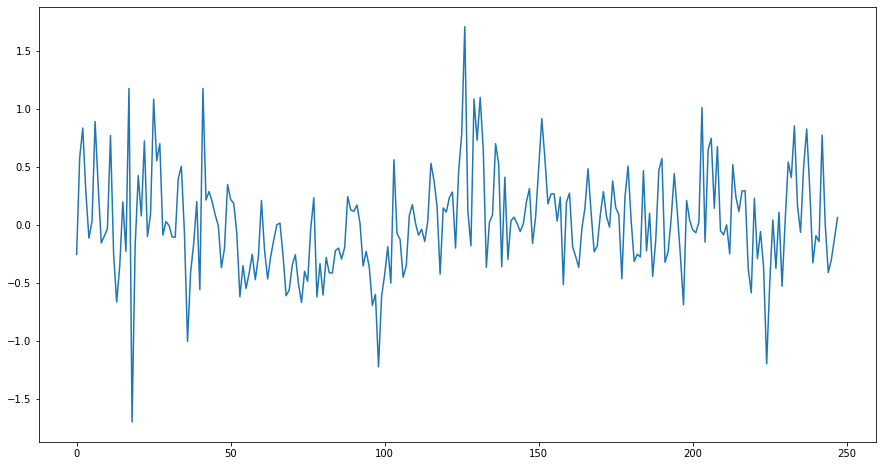

In [93]:
calc_business_metric_diff(X_test, y_test)

-17.709948350243792


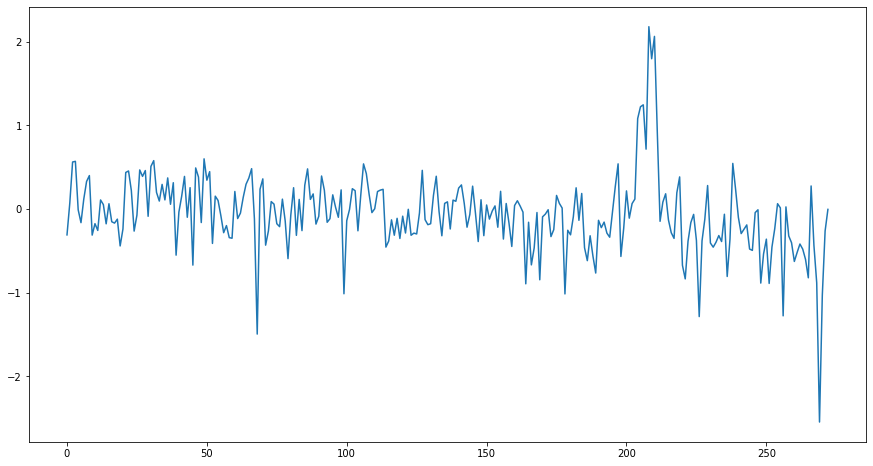

In [94]:
calc_business_metric_diff(X_val, y_val)
#не ок, вариант с полноценной моделью Баланса лучше, как видим

Мы рассмотрели не только ошибку MAE для двух возможных вариантах предсказания баланса, но и посмотрели как будет вести себя бизнес-метрика - доходность с алгоритма. 

Так как наша валидационная выборка начинается с марте 2020 года, есть предположение, что в этот момент должны происходить всякие разладки и аномалии в данных.
Поэтому когда мы будем использовать модель с разностью двух предсказаний, мы будем накапливать их ошибки: недопредсказанный Outcome и переоцененный Income будут сильно влиять на качество этой метрики. 
Поэтому вариант со взятием разницы считаем менее эффективным и дальше будем использовать модель для Баланса

# Anomaly detection

В этом блоке будем искать в какой момент происходит разладка. 

# Первый метод


Проверка, что новые значения Х - похожи на предыдущие. 

Ограничения: 

- сколько брать предыдущих значений

- каким распределением апроксимировать

- какой взять порог 'p_val'

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import plot
from datetime import datetime
from scipy.stats import ttest_ind

x_old = pd.DataFrame()
x_old['Income'] = np.random.normal(loc=300, scale=100.0, size=50)
x_old['Outcome'] = np.random.normal(loc=270, scale=100.0, size=50)

def is_newline_normal(x_old, x_new_line):
    ## null H: new line 
    for col in x_old.columns:

        old_mean = x_old[col].mean()
        old_std = x_old[col].std()

        x_old_boosted = np.random.normal(loc=old_mean, scale=old_std, size=5000)
        if x_new_line[col] > old_mean:
            mask = x_old_boosted > x_new_line[col]
            p_val_custom = len(x_old_boosted[mask]) / len(x_old_boosted)
        else:
            mask = x_old_boosted < x_new_line[col]
            p_val_custom = len(x_old_boosted[mask]) / len(x_old_boosted)
        print('with prob= ', p_val_custom, f'we consider new line {col} as ', end = '')
        print('normal!') if p_val_custom > 0.05 else print('anomal')

x_new_line = {'Income': 500, 'Outcome': 300}

is_newline_normal(x_old, x_new_line)
is_newline_normal(x_old, {'Income': 100, 'Outcome': 250})

with prob=  0.0078 we consider new line Income as anomal
with prob=  0.4148 we consider new line Outcome as normal!
with prob=  0.0074 we consider new line Income as anomal
with prob=  0.415 we consider new line Outcome as normal!


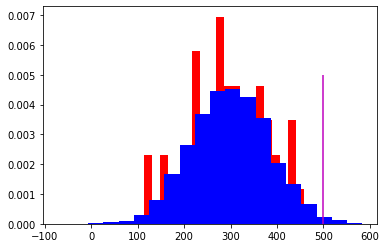

In [119]:
import matplotlib.pyplot as plt 
x_old_boosted = np.random.normal(loc=x_old.Income.mean(), scale=x_old.Income.std(), size=5000)

# with prob=  0.0276 we consider new line Income as anomal
plt.figure()
plt.hist(x_old.Income, color = 'red', density = True, bins = 20)
plt.hist(x_old_boosted, color = 'blue', density = True, bins = 20)
plt.vlines(x = x_new_line['Income'], ymin = 0, ymax = 0.005, color = 'm')

# Второй метод
Проверка на нормальные значения предсказаний. 
Берем значения ошибки на предыдущих этапах и проверяем, что качество не снижается и находится в допустимых пределах (заданных заказчиком)

Ограничения:

- какой порог нормальной метрики выдает заказчик

- сколько предыдущих наблюдений брать, чтобы отловить тренд на снижение?

[-0.98354557  1.77602378]


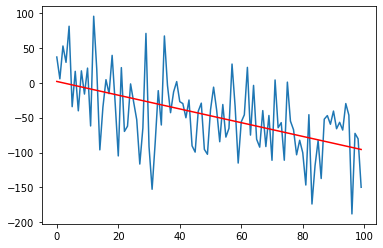

In [120]:
rng = np.random.default_rng()
x = np.arange(100)
y = - np.arange(100) - 50 * rng.standard_normal(100)

a = np.polyfit(x, y, deg=1)
print(a)
plot(x, y)
y_pred = a[1] + a[0] * x

plot(x, y_pred, 'r')

In [122]:
def check_quality(quality: DataFrame, period_before, norm_quality, bad_angle = -0.1):
    quality = quality.iloc[-period_before:, :]
    if any(quality < norm_quality):
        print('Got low predicted quality, please check the model')
    x = np.arange(len(quality))
    a = np.polyfit(x, quality, deg=1)
    if a[1] < bad_angle:
        print('Model quality is getting worse, please check the model')

# CUMSUM

Этот метод сначала вычисляет среднее значение временного ряда, затем он вычитает это среднее из каждого значения временного ряда. Таким образом, полученный временной ряд центрируется вокруг 0.

Затем вычисляется временной ряд кумулятивных сумм значений в центрированном временном ряду. Наконец, он обнаруживает точки во временном ряду кумулятивных сумм, в которых их значение резко меняется. Он отмечает эти точки как точки изменения.

In [123]:
dd_remove_dates.head(2)

,Date,bid,Income,Outcome,Balance,Year,Month,DayofWeek,DayofMonth,bid_days_change,...,balance_angle_27,income_angle_28,outcome_angle_28,balance_angle_28,income_angle_29,outcome_angle_29,balance_angle_29,income_angle_30,outcome_angle_30,balance_angle_30
0,2017-02-20,10.0,1.119653,1.144411,-0.024759,2017,2,0,20,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2017-02-21,10.0,1.287537,1.156468,0.131069,2017,2,1,21,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Change points indices: [23, 60, 89, 106, 139, 167, 194, 208, 221, 253, 272, 296, 321, 336, 351, 376, 397, 417, 439, 462, 479, 493, 512, 522, 541, 557, 574, 592, 605, 628, 651, 675, 699, 718, 735, 764, 795, 818, 845, 874, 910, 928, 947, 969, 981, 998, 1011, 1019]


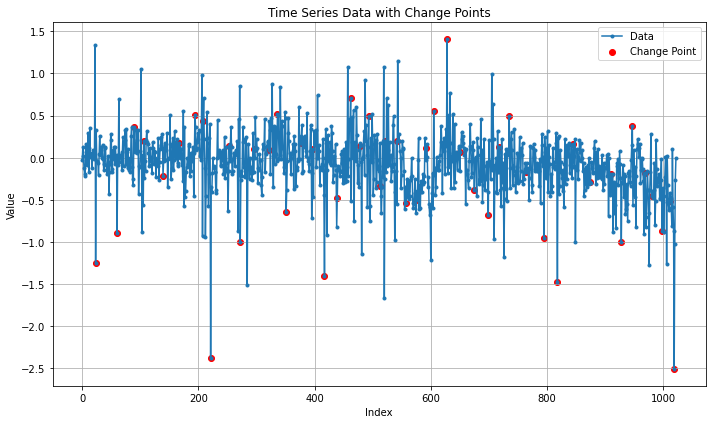

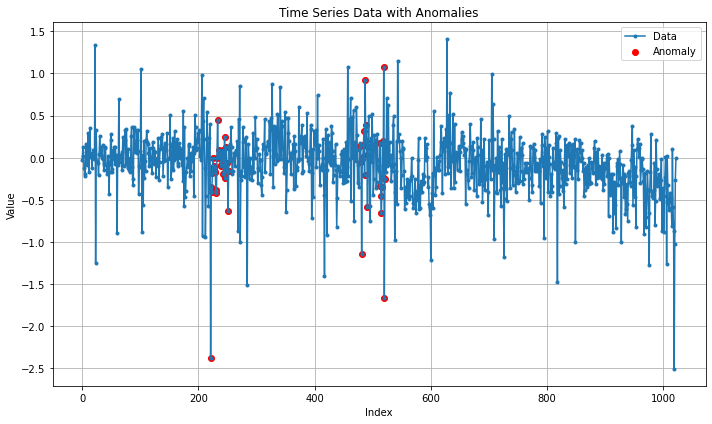

In [141]:
def cusum(data, threshold):

    mean = np.mean(data)
    cumulative_sum = 0
    change_points = []

    for i, x in enumerate(data):
        cumulative_sum += abs(x - mean)
        if cumulative_sum > threshold:
            change_points.append(i)
            cumulative_sum = 0  #сброс

    return change_points

data = dd_remove_dates.Balance #наш датафрейм


threshold = 5
anomaly_threshold = 2  #можно менять

change_points = cusum(data, threshold)
print("Change points indices:", change_points)

plt.figure(figsize=(10, 6))
plt.plot(range(len(data)), data, marker='.', label='Data')
plt.scatter(change_points, [data[i] for i in change_points], color='red', label='Change Point')
plt.title('Time Series Data with Change Points')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

anomalies = []
for i in range(len(change_points) - 1):
    start_index = change_points[i]
    end_index = change_points[i + 1]
    segment = data[start_index:end_index]
    if max(segment) - min(segment) > anomaly_threshold:
        anomalies.extend(range(start_index, end_index))

plt.figure(figsize=(10, 6))
plt.plot(range(len(data)), data, marker='.', label='Data')
plt.scatter(anomalies, [data[i] for i in anomalies], color='red', label='Anomaly')
plt.title('Time Series Data with Anomalies')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Final pipeline

# Общий пайплайн
До запуска в прод:

1. Провели EDA, обработали аномалии, добавили потенциально нужные внегние признаки - feature engineering 
2. Проверили отбор на самые важные признаки - Feature selection
3. Обучили и затюнили конкурентные модели
4. Выбрали модель
5. Проверили графики качества и при необходимости выделили доп фичи
6. Зафиксировали нормальные метрики и нормальные распределения данных

В проде:

1. Получили новые данные
2. Проверили качество входных данных - само распределение Х
3. Проверили алгоритмом changepoint detection
4. Дообучились по предыдущим "новым" полученным данным - если сейчас период дообучения
5. Сделали прогноз на новых данных
6. Проверили, что качество на прогнозе все еще норм - post-processing 
7. Проверили интерпретируемость выданных прогнозов6 отрисовали графики
8. Если нужно, отправили алерт
9. Если нужно начали собирать новый датасет для последующего обучения модели


In [175]:
from dataclasses import dataclass, asdict
from enum import Enum
from abc import ABC, abstractmethod


@dataclass
class GBRParams:
    alpha = 0.015
    learning_rate = 0.02
    loss = 'quantile'
    max_depth = 10
    n_estimators = 1500
    random_state = 42
    subsample = 0.5

@dataclass
class AdaBoostParams:
    learning_rate = 0.1
    n_estimators = 2000 
    random_state = 42

class PipelineStates(str, Enum):
    normal = 'normal'
    outlier = 'outlier'
    anomaly = 'anomaly'
    degrade = 'degrade'


class CheckerModes(str, Enum):
    anomaly = 'anomaly'
    change_points = 'change_points'
    target = 'target'

class AnomalyDetector(ABC):
    @abstractmethod
    def check(self, ref: pd.DataFrame, cur: pd.DataFrame, **kwargs) -> bool:
        pass

In [176]:
class GBRTimeSeriesModel:
    def __init__(self, data_x: np.ndarray, data_y: np.ndarray, params: GBRParams):
        self.__model = GradientBoostingRegressor(**asdict(params))
        self.__model.fit(data_x, data_y)

    def predict(self, x: np.ndarray):
        return self.__model.predict(x)
    

class AdaBoostTimeSeriesModel:
    def __init__(self, data_x: np.ndarray, data_y: np.ndarray, params: AdaBoostParams):
        self.__model = AdaBoostRegressor(**asdict(params))
        self.__model.fit(data_x, data_y)

    def predict(self, x: np.ndarray):
        return self.__model.predict(x)

In [177]:
class BootstrapDetector(AnomalyDetector):
    def check(self, ref: pd.DataFrame, cur: pd.DataFrame, **kwargs) -> int:

        assert len(set(ref.columns) ^ set(cur.keys())) == 0, 'Column lists are not comparable'

        count = 0
        for column in ref.columns:
            old_mean = ref[column].mean()
            old_std = ref[column].std()

            x_old_boosted = np.random.normal(loc=old_mean, scale=old_std, size=5000)
            if cur[column] > old_mean:
                mask = x_old_boosted > cur[column]
                p_val_custom = len(x_old_boosted[mask]) / len(x_old_boosted)
            else:
                mask = x_old_boosted < cur[column]
                p_val_custom = len(x_old_boosted[mask]) / len(x_old_boosted)

            if p_val_custom < 0.05:
                count += 1
        return count

In [178]:
class OutputChecker(AnomalyDetector):
    def check(self, ref: np.ndarray, cur: np.ndarray, bad_angle=-0.05, **kwargs) -> int:
        count = 0
        if np.mean(cur) < np.mean(ref) - np.std(ref):
            count += 1

        x = np.arange(len(cur))
        a = np.polyfit(x, cur, deg=1)

        if a[1] < bad_angle:
            count += 1

        return count

In [200]:
class CumSumDetector(AnomalyDetector):
    def __init__(self, change_point_threshold: int = 5, anomaly_threshold: int = 2):
        self.__change_point_threshold = change_point_threshold
        self.__anomaly_threshold = anomaly_threshold

    def __change_points(self, data: pd.Series):
        mn = np.mean(data.to_numpy())
        cumulative_sum = 0
        change_points = []

        for i, x in enumerate(data):
            cumulative_sum += abs(x - mn)
            if cumulative_sum > self.__change_point_threshold:
                change_points.append(i)
                cumulative_sum = 0

        return change_points

    def __anomalies(self, data: pd.Series):
        change_points = self.__change_points(data)
        data = data.to_numpy()

        anomalies = []
        for i in range(len(change_points) - 1):
            start_index = change_points[i]
            end_index = change_points[i + 1]
            segment = data[start_index:end_index]
            if max(segment) - min(segment) > self.__anomaly_threshold:
                anomalies.extend(range(start_index, end_index))

        return anomalies

    def check(self, data: pd.DataFrame, mode: CheckerModes = CheckerModes.anomaly, **kwargs) -> int:
        if mode == CheckerModes.anomaly:
            checker = self.__anomalies
        elif mode == CheckerModes.change_points:
            checker = self.__change_points
        elif mode == CheckerModes.target:
            checker = self.__anomalies
        else:
            raise NotImplementedError(f'Mode {mode} is not implemented')

        count = 0

        if mode == CheckerModes.target:
            return int(len(data) - 1 in checker(data))

        for col in data.columns:
            points = checker(data[col])

            if mode == CheckerModes.change_points:
                if len(data) - 1 in points:
                    count += 1
            elif mode == CheckerModes.anomaly:
                if len(points) > 0:
                    count += 1

        return count

In [220]:
class Pipeline:
    def __init__(
            self,
            simple_detector: AnomalyDetector,
            anomaly_detector: AnomalyDetector,
            output_checker: AnomalyDetector,
            model: GBRTimeSeriesModel,
            model_params: GBRParams,
            model_creator: type = AdaBoostTimeSeriesModel,
            refit_period: int = 30,
            init_period: int = 400,
            rate_column: str = 'bid',
            outliers_cols: list = None,
    ):
        self.__model = model
        self.__model_params = model_params
        self.__model_creator = model_creator

        self.__simple_detector = simple_detector
        self.__anomaly_detector = anomaly_detector
        self.__output_checker = output_checker

        self.__refit_period = refit_period
        self.__init_period = init_period
        self.__rate_column = rate_column

        if outliers_cols is None:
            self.__outliers_cols = []
        else:
            self.__outliers_cols = outliers_cols

    @staticmethod
    def __business_metrics(
            balance_prediction: float,
            balance_actual: float,
            cur_rate: float
    ) -> float:
        """
        Возвращаем daily_income - сколько заработали (или потратили) в день
        Его нужно сложить со всеми предыдущими значениями в процессе обучения
        :param balance_prediction: предсказание, сделанное для сегодняшнего дня (с сегодняшнего утра на сегодняшний вечер)
        :param balance_actual: реализация для сегодняшнего дня (что узнаем вечером)
        :param cur_rate: текущая ставка
        :return: сколько заработали (или потратили) в день
        """
        # for example (10%-0.9%) / 365 = 9.1%/365 = 0.02493150684931507 % per day
        profit_overnight = (cur_rate - 0.9) / 365
        defit_overnight = (cur_rate + 1) / 365
        derivatives_rate = (cur_rate + 0.5) / 365

        # моделируем утро
        daily_income = 0
        if balance_prediction > 0:
            daily_income += balance_prediction * (1 + derivatives_rate)

        # моделируем вечер, уже знаем balance_actual
        if balance_actual - balance_prediction < 0:
            # мы в состоянии дефицита: предсказали больше, чем получили в итоге
            daily_income += (balance_actual - balance_prediction) * (1 + defit_overnight)
        else:
            # мы в состоянии профицита: предсказали больше, чем получили в итоге
            daily_income += (balance_actual - balance_prediction) * (1 + profit_overnight)

        return daily_income

    def __process_one_day(self, data: pd.DataFrame, target: pd.Series):
        # сначала у нас все хорошо
        state = PipelineStates.normal

        # проверяем новый день на предмет соответствия старым распределениям
        count_boot = self.__simple_detector.check(data[self.__outliers_cols][:-1], data[self.__outliers_cols].iloc[-1])
        count_anomaly_change = self.__anomaly_detector.check(data[self.__outliers_cols], mode=CheckerModes.change_points)

        # если не соответствует, то посылаем аллерт
        if (count_boot > 0) or (count_anomaly_change > 0):
            warnings.warn('Outlier detected. Continue processing...')
            state = PipelineStates.outlier

        # проверяем, нет ли у нас разладки по фичам
        if self.__anomaly_detector.check(data[self.__outliers_cols], mode=CheckerModes.anomaly) > 0:
            warnings.warn('Anomaly in features detected. Processing is stopped!')
            return PipelineStates.anomaly, 0, 0

        # проверяем, нет ли у нас разладки по таргетам за день до этого (вообще, мы это и в первом пункте поймаем
        # за счет лага, но на всякий случай
        if self.__anomaly_detector.check(target.iloc[:-1], mode=CheckerModes.target) > 0:
            warnings.warn('Anomaly in target detected. Processing is stopped!')
            return PipelineStates.anomaly, 0, 0

        # если все ок, то получаем предсказания за текущий день
        prediction = self.__model.predict(data.iloc[-1].to_frame().T)[0]
        metric = self.__business_metrics(prediction, target.iloc[-1], data[self.__rate_column].iloc[-1])

        # возвращаем статус, предсказания и бизнес метрику
        return state, prediction, metric

    def entry(self, data: pd.DataFrame, target: pd.Series):

        # создаем пустые массивы для хранения результатов
        preds, metrics = np.empty(0), np.empty(0)
        lag = self.__init_period + 1

        # перебираем последовательно все элементы, симулируем работу по дням
        for idx in tqdm(range(lag, len(data))):

            # если прошел цикл переобучения и при этом это был не первый цикл, то делаем проверку метрик
            if (idx - lag > 0) and ((idx - lag) % self.__refit_period == 0):

                window = [idx - self.__refit_period - lag, idx - lag]
                if metrics.shape[0] >= self.__refit_period * 2:
                    ref = metrics[window[0] - self.__refit_period:window[1] - self.__refit_period]
                    cur = metrics[window[0]:window[1]]
                    out_count = self.__output_checker.check(ref, cur)

                    # если нашли проблемы, то пишем предупреждение
                    if out_count > 0:
                        warnings.warn('Model quality is getting worse, please check the model')

                # переобучаем модель в конце цикла
                self.__model = self.__model_creator(
                    data[:idx],
                    target[:idx],
                    self.__model_params
                )

            # обрабатываем новый день
            state, pred, metr = self.__process_one_day(data[:idx], target[:idx])

            # если нам вернули статус с аномалией, то сворачиваемся
            if state == PipelineStates.anomaly:
                break

            # сохраняем предсказания и метрики
            preds = np.append(preds, pred)
            metrics = np.append(metrics, metr)

        return preds, metrics

In [221]:
init_period = 400
refit_period = 30
# refit_periods = np.arange(10) + 25
cols = [col for col in dd_remove_dates.columns if 'lag' in col or col == 'bid']

drop_cols = ['Date', 'Income', 'Outcome', 'Balance']
x = dd_remove_dates.dropna().drop(columns=drop_cols)
y = dd_remove_dates.dropna().Balance

In [222]:
params = AdaBoostParams()
model = AdaBoostTimeSeriesModel(x[:init_period], y[:init_period], params)

In [223]:
warnings.filterwarnings('default')

In [225]:
pred = Pipeline(
        model=model,
        simple_detector=BootstrapDetector(),
        anomaly_detector=CumSumDetector(change_point_threshold=15, anomaly_threshold=4),
        output_checker=OutputChecker(),
        model_params=params,
        refit_period=30,
        outliers_cols=cols,
    )
pipeline_preds, pipeline_metrics = pred.entry(x, y)
#ворнинги работают, при детекции аномалии  'warnings.warn('Anomaly in features detected. Processing is stopped!')
#пайплайн остановился

  0%|          | 0/622 [00:00<?, ?it/s]

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:117: UserWarning: Model quality is getting worse, please check the model
  warnings.warn('Model quality is getting worse, please check the model')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue pr

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

... (2 outputs left out)

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_/m83chgx52fn_xqgyxlnvpwlh0000gp/T/ipykernel_37595/2595952065.py:76: UserWarning: Outlier detected. Continue processing...
  warnings.warn('Outlier detected. Continue processing...')
/var/folders/5_

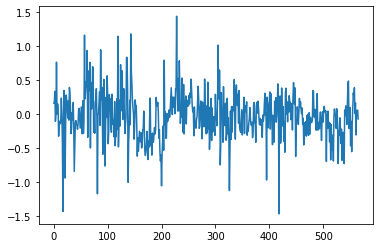

In [226]:
plt.plot(np.arange(len(pipeline_metrics)), pipeline_metrics)
#предикты бизнесовой метрики

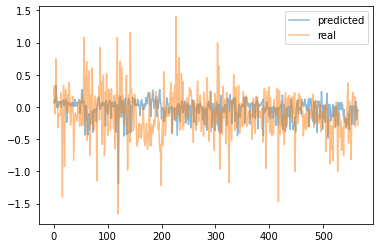

In [229]:
plt.plot(np.arange(len(pipeline_preds)), pipeline_preds, label='predicted', alpha = 0.5)
plt.plot(np.arange(len(pipeline_preds)), dd_remove_dates.Balance[init_period+1:init_period+1+len(pipeline_preds)], 
         label='real', alpha = 0.5)
plt.legend()
plt.show()

#предикты vs реальные значения для той части данных, на которых отработал пайплайн до остановки